# PAMMELA: Policy Administration Methodology using Machine Learning
**Research Paper Implementation & Adversarial Robustness Evaluation**

---

### Citation
> **Paper:** Varun Gumma, Barsha Mitra, Soumyadeep Dey, Pratik Shashikantbhai Patel, Sourabh Suman, Saptarshi Das, and Jaideep Vaidya.  
> *"PAMMELA: Policy Administration Methodology using Machine Learning."*  
> In **Proceedings of the 19th International Conference on Security and Cryptography (SECRYPT 2022)**, pages 147–157.  
> DOI: [10.5220/0011272400003283](https://doi.org/10.5220/0011272400003283)

---

### Executive Summary & Problem Formulation
Attribute-Based Access Control (**ABAC**) provides fine-grained, dynamic access control based on subject, object, and environmental attributes. However, designing and maintaining ABAC policies *ab initio* or re-mining an entire policy after organizational changes demands immense administrative overhead and causes system downtime.

To address this challenge, the authors introduce the **ABAC Policy Inference Problem (ABAC-PIP)** and propose **PAMMELA** (**P**olicy **A**dministration **M**ethodology using **M**achin**E** **L**e**A**rning).

#### Two Core Application Scenarios:
1. **Augmentative Policy Inference:** Incremental generation of additional ABAC rules when an organization introduces new departments, academic degrees, or resource types without re-mining the entire policy.
2. **Adaptive Policy Inference:** Adapting a mature reference ABAC policy from an existing organization to bootstrap access control for a newly migrating or similar organization.

#### Two-Phase Machine Learning Workflow:
- **Phase 1 (Training):** A supervised machine learning classifier is trained on the deployed ABAC policy. Training includes both **positive rules** ($PR$, accesses granted) and **negative rules** ($NR = U \setminus PR$, accesses denied) derived from the universe $U$ of attribute-value pairings.
- **Phase 2 (Testing & Rule Inference):** Given new access requests containing newly introduced attribute values, the trained classifier predicts whether each request should be permitted (`YES` / $1$) or denied (`NO` / $0$), synthesizing concrete ABAC rules for administrator review.

---

### Scope of this Notebook
1. **Part I: Paper Implementation & Benchmark Verification:**
   - Data Ingestion & Cleaning for **University Dataset 1** (53 initial rules, 1,010 test requests).
   - Exploratory Data Analysis (EDA) of roles, departments, and resource categories.
   - Negative rule generation ($NR = U \setminus PR$) and monotonic categorical encoding.
   - Training 6 ML classifiers: **ANN, Decision Tree (DT), Random Forest (RF), Extra Trees (ET), Gradient Boosting (GB), and XGBoost (XGB)**.
   - Direct verification against published results in **Table 4 of SECRYPT 2022**.
   - Automated rule generation for system administrators.
2. **Part II: Adversarial Security & Categorical Evasion Attack:**
   - Formulation of the discrete categorical evasion threat model ($L_0$ / Hamming distance budget $\le 1$).
   - Executing the categorical evasion attack on all 6 trained classifiers.
   - Comparing model metrics **Before vs After Attack** (Accuracy, Precision, Recall, F1-Score, ASR, FPA).
   - In-depth Matplotlib visualizations: Performance drops, ASR rankings, confusion matrix shifts, and exploited attribute distributions.
   - Discussion of defenses: Discrete Adversarial Training, Relational Feature Engineering, and Hybrid Verifiers.

In [1]:
# =====================================================================
# 1. ENVIRONMENT SETUP & DEPENDENCY IMPORTS
# =====================================================================

import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn Classifiers & Metrics
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc,
    precision_recall_curve, average_precision_score
)
from xgboost import XGBClassifier

# Suppress minor warnings for clean presentation
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure Matplotlib aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10

# Configure output directories
BASE_DIR = os.path.dirname(os.path.abspath('__file__')) if '__file__' in locals() else os.getcwd()
DATASET_DIR = os.path.join(BASE_DIR, 'dataset')
PLOTS_DIR = os.path.join(BASE_DIR, 'plots')
os.makedirs(PLOTS_DIR, exist_ok=True)

print(f"Base Directory   : {BASE_DIR}")
print(f"Dataset Directory: {DATASET_DIR}")
print(f"Plots Directory  : {PLOTS_DIR}")
print("Dependencies successfully imported and environment configured.")


Base Directory   : C:\Users\patel\Documents\Studies\Academics\SEM-5\Design Project\pammela implementation
Dataset Directory: C:\Users\patel\Documents\Studies\Academics\SEM-5\Design Project\pammela implementation\dataset
Plots Directory  : C:\Users\patel\Documents\Studies\Academics\SEM-5\Design Project\pammela implementation\plots
Dependencies successfully imported and environment configured.


---
## 2. Dataset Ingestion & Preprocessing

The paper evaluates PAMMELA on three datasets. Here, we utilize **University Dataset 1**, which mimics an educational institution's workflow.

### Attribute Structure (Table 1 & Table 3 of the Paper):
| Attribute Type | Attribute Name | Training Values Count (Table 1) | New Test Values Count (Table 3) | New Test Values Description |
| :--- | :--- | :---: | :---: | :--- |
| **Subject** | `Designation` | 3 (`stu`, `prof`, `officer`) | 2 | `vis_prof` (Visiting Prof), `adj_prof` (Adjunct Prof) |
| **Subject** | `Department` | 4 (`cse`, `ece`, `ce`, `me`) | 5 | `IT`, `eni`, `pha`, `chem`, `accounts` |
| **Subject** | `Degree` | 2 (`btech`, `mtech`) | 2 | `BE`, `ME` |
| **Subject** | `Year` | 4 (`1`, `2`, `3`, `4`) | 0 | None (Same 4 years) |
| **Object** | `Resource-Type` (`Type`) | 7 (`asgn`, `std_mat`, `q_pr`, `attdn`, `grade_book`, `stu_rec`, `off_rec`) | 3 | `quiz`, `proj` (Projects), `dept_bud` (Dept Budget) |
| **Object** | `Department` | 4 (`cse`, `ece`, `ce`, `me`) | 4 | `IT`, `eni`, `pha`, `chem` |
| **Object** | `Degree` | 2 (`btech`, `mtech`) | 2 | `BE`, `ME` |
| **Object** | `Year` | 4 (`1`, `2`, `3`, `4`) | 0 | None (Same 4 years) |

### Key Dataset Quantities (Table 2 of the Paper):
- **Rule Count in Training Policy ($P$):** 53 rules
- **Total Test Access Requests ($L$):** 1,010 requests
- **Positive Test Requests (Permitted / Allow = 1):** 598 requests
- **Negative Test Requests (Denied / Deny = 0):** 412 requests


In [2]:
# =====================================================================
# 2. DATA INGESTION & DATASET VALIDATION
# =====================================================================

pol_file = os.path.join(DATASET_DIR, 'pol_data-v1.csv')
sub_file = os.path.join(DATASET_DIR, 'sub_data.csv')
obj_file = os.path.join(DATASET_DIR, 'obj_data.csv')
test_file = os.path.join(DATASET_DIR, 'model_ABAC_new_test_data_set.csv')

# Load raw datasets
pol_df = pd.read_csv(pol_file)
sub_df = pd.read_csv(sub_file)
obj_df = pd.read_csv(obj_file)
test_df = pd.read_csv(test_file)

print("="*70)
print("RAW DATASET INGESTION SUMMARY")
print("="*70)
print(f"Policy Rules File (pol_data-v1.csv) : Shape {pol_df.shape}")
print(f"Subject Profiles File (sub_data.csv) : Shape {sub_df.shape}")
print(f"Object Profiles File (obj_data.csv)  : Shape {obj_df.shape}")
print(f"Test Access Requests File           : Shape {test_df.shape}")

# Standardize missing values (Not Applicable) to 'NA'
sub_df = sub_df.fillna('NA')
obj_df = obj_df.fillna('NA')
test_df['Degree'] = test_df['Degree'].fillna('NA')
test_df['Year'] = test_df['Year'].fillna('NA')
test_df['Degree.1'] = test_df['Degree.1'].fillna('NA')
test_df['Year.1'] = test_df['Year.1'].fillna('NA')

# Standardize year formatting (remove floating point representation)
sub_df['Year'] = sub_df['Year'].astype(str).str.replace('.0', '', regex=False)
obj_df['Year'] = obj_df['Year'].astype(str).str.replace('.0', '', regex=False)
test_df['Year'] = test_df['Year'].astype(str).str.replace('.0', '', regex=False)
test_df['Year.1'] = test_df['Year.1'].astype(str).str.replace('.0', '', regex=False)

print("\nSample 5 Policy Rules from Initial Policy Database (P):")
print(pol_df.head(5).to_string(index=False))

print("\nSample 5 Test Access Requests from L:")
print(test_df.head(5).to_string(index=False))

print("\nTest Target Distribution (Perm):")
print(test_df['Perm'].value_counts().rename({1: 'Allow (Positive = 1)', 0: 'Deny (Negative = 0)'}))


RAW DATASET INGESTION SUMMARY
Policy Rules File (pol_data-v1.csv) : Shape (53, 8)
Subject Profiles File (sub_data.csv) : Shape (700, 4)
Object Profiles File (obj_data.csv)  : Shape (1348, 4)
Test Access Requests File           : Shape (1010, 9)

Sample 5 Policy Rules from Initial Policy Database (P):
Designation Department Degree Year Type Department.1 Degree.1 Year.1
        stu        cse  btech    1 asgn          cse    btech      1
        stu        ece  btech    1 asgn          ece    btech      1
        stu         ce  btech    1 asgn           ce    btech      1
        stu         me  btech    1 asgn           me    btech      1
        stu        cse  btech    2 asgn          cse    btech      2

Sample 5 Test Access Requests from L:
Designation Department Degree Year Type Department.1 Degree.1 Year.1  Perm
        stu         IT  btech    1 asgn           IT    btech      1     1
        stu        eni  btech    1 asgn          eni    btech      1     1
        stu        p

---
## 3. Exploratory Data Analysis (EDA)

We explore the distributions of attributes across subjects, resources, and access decisions to verify alignment with the paper's descriptions.


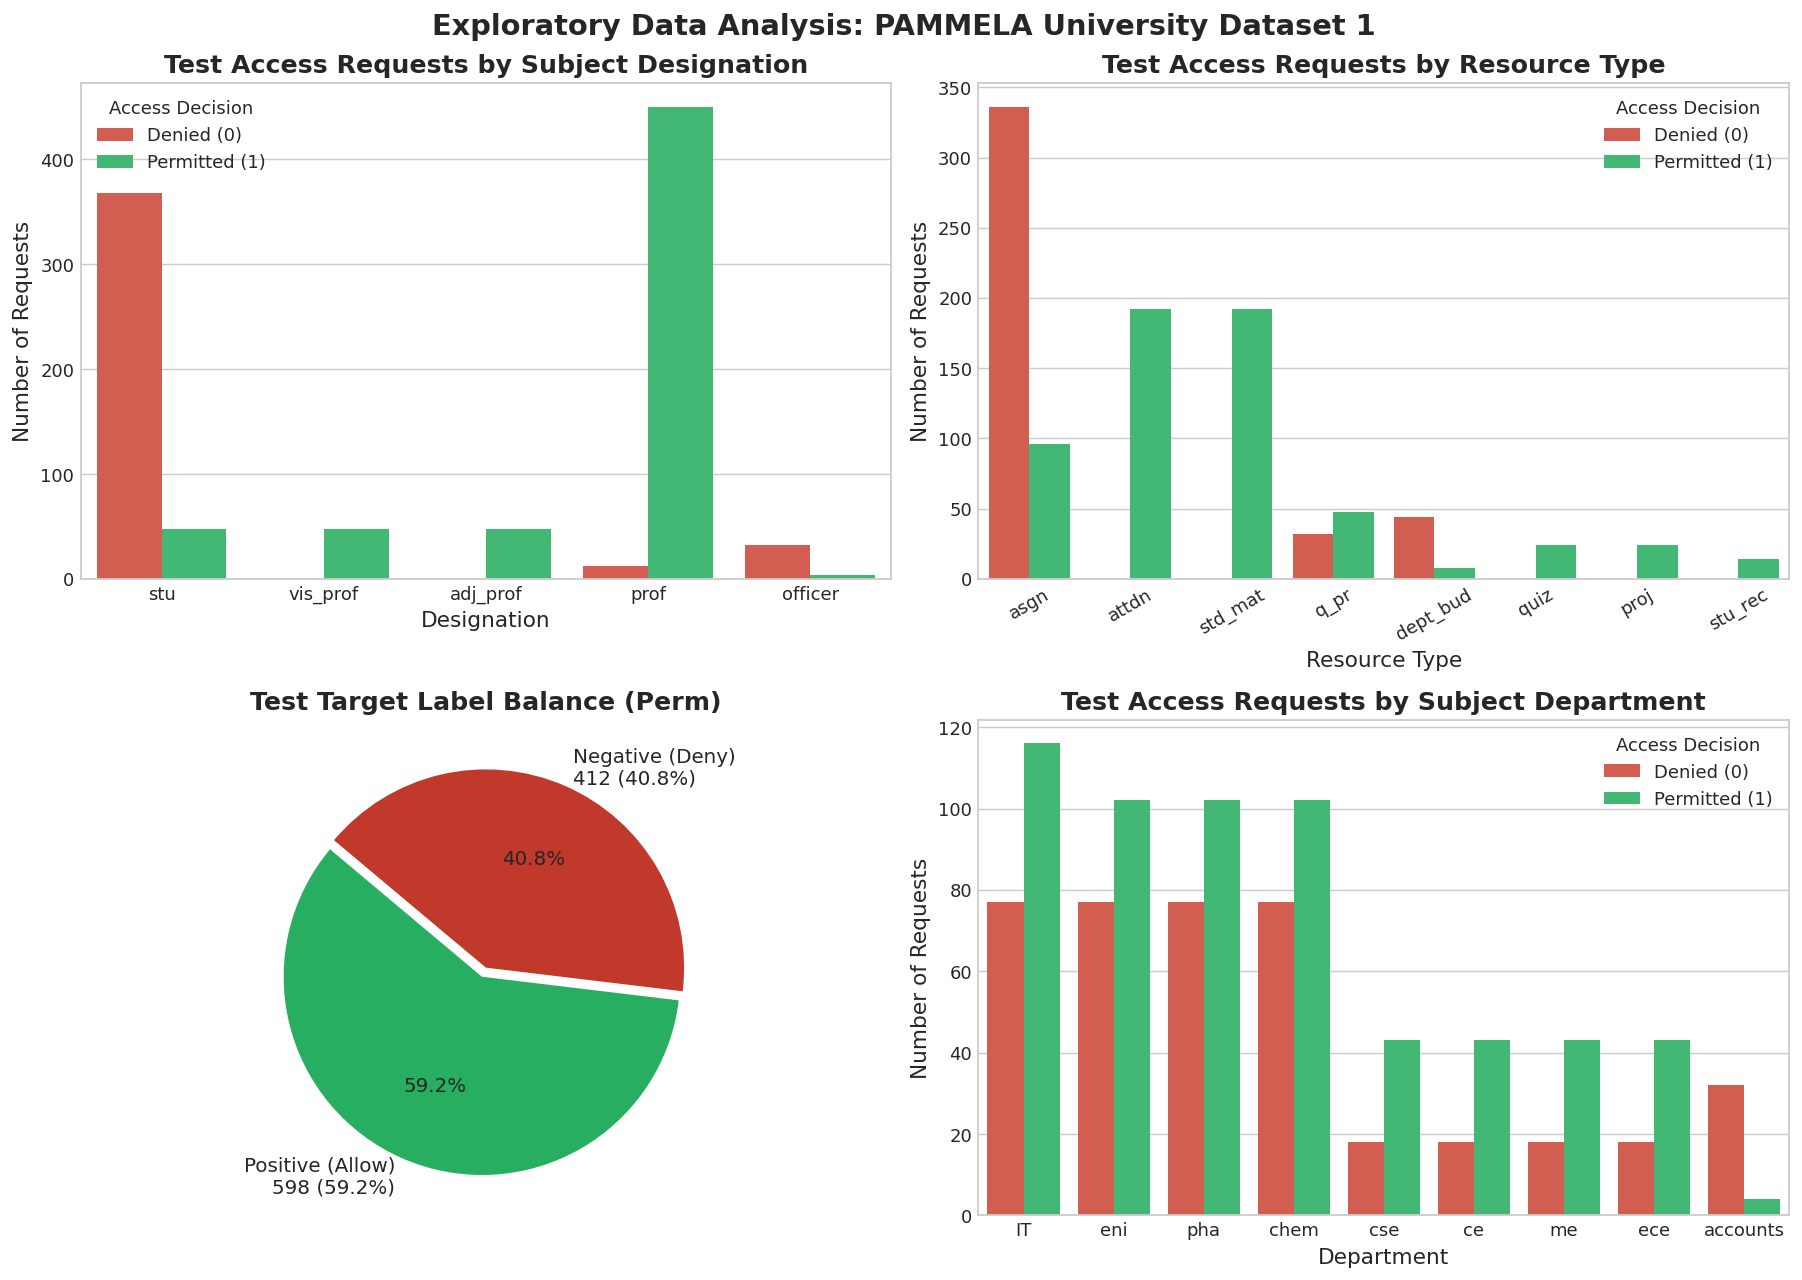

In [3]:
# =====================================================================
# 3. EXPLORATORY DATA ANALYSIS (EDA) & VISUALIZATION
# =====================================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Exploratory Data Analysis: PAMMELA University Dataset 1', fontsize=16, fontweight='bold', y=0.98)

# 1. Subject Designation Distribution in Test
sns.countplot(
    data=test_df, x='Designation', hue='Perm',
    palette={1: '#2ecc71', 0: '#e74c3c'}, ax=axes[0, 0]
)
axes[0, 0].set_title('Test Access Requests by Subject Designation', fontweight='bold')
axes[0, 0].set_xlabel('Designation')
axes[0, 0].set_ylabel('Number of Requests')
axes[0, 0].legend(['Denied (0)', 'Permitted (1)'], title='Access Decision')

# 2. Resource Type Distribution in Test
order_types = test_df['Type'].value_counts().index
sns.countplot(
    data=test_df, x='Type', hue='Perm', order=order_types,
    palette={1: '#2ecc71', 0: '#e74c3c'}, ax=axes[0, 1]
)
axes[0, 1].set_title('Test Access Requests by Resource Type', fontweight='bold')
axes[0, 1].set_xlabel('Resource Type')
axes[0, 1].set_ylabel('Number of Requests')
axes[0, 1].tick_params(axis='x', rotation=30)
axes[0, 1].legend(['Denied (0)', 'Permitted (1)'], title='Access Decision')

# 3. Target Distribution (Allow vs Deny)
perm_counts = test_df['Perm'].value_counts()
labels = [f"Positive (Allow)\n{perm_counts[1]} ({perm_counts[1]/len(test_df)*100:.1f}%)",
          f"Negative (Deny)\n{perm_counts[0]} ({perm_counts[0]/len(test_df)*100:.1f}%)"]
axes[1, 0].pie(
    perm_counts, labels=labels, autopct='%1.1f%%',
    startangle=140, colors=['#27ae60', '#c0392b'],
    explode=(0.05, 0), textprops={'fontsize': 11}
)
axes[1, 0].set_title('Test Target Label Balance (Perm)', fontweight='bold')

# 4. Department-wise Requests in Test Data
sns.countplot(
    data=test_df, x='Department', hue='Perm',
    palette={1: '#2ecc71', 0: '#e74c3c'}, ax=axes[1, 1]
)
axes[1, 1].set_title('Test Access Requests by Subject Department', fontweight='bold')
axes[1, 1].set_xlabel('Department')
axes[1, 1].set_ylabel('Number of Requests')
axes[1, 1].legend(['Denied (0)', 'Permitted (1)'], title='Access Decision')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '01_eda_dataset_distributions.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 4. Phase 1: Policy Engine & Negative Rule Generation ($NR = U \setminus PR$)

In ABAC, a deployed policy contains a set of **positive rules** ($PR$) explicitly defining allowed combinations of subject and resource attributes.

As emphasized in Section 5.1 of the paper:
> *"In addition to positive rules, it is also essential for the classifier to learn when an access request is to be denied. Such scenarios are covered by negative rules... If $U$ denotes the set of all possible attribute-value pairings and $PR$ denotes the set of positive rules, then the set of negative rules $NR = \{U\} \setminus \{PR\}$."*

Training exclusively on positive rules causes standard classifiers to fail because they never encounter the deny decision. Thus, PAMMELA constructs the universe $U$ from the organizational subject profiles ($S$) and object profiles ($O$), evaluates each candidate access request against the 53 policy rules $P$, and generates a fully labeled training set containing both permitted and denied accesses.

In [4]:
# =====================================================================
# 4. ABAC POLICY RULE ENGINE & TRAINING SET CONSTRUCTION
# =====================================================================

def evaluate_abac_rule_match(subj, obj, pol_rules):
    # Evaluates whether an access request between a subject and an object
    # satisfies any positive rule in the deployed ABAC policy P.
    # 'X' acts as a wildcard ('Any' / 'Not Applicable').
    for _, rule in pol_rules.iterrows():
        # Match Subject Attributes
        if rule['Designation'] != 'X' and rule['Designation'] != subj['Designation']:
            continue
        if rule['Department'] != 'X' and rule['Department'] != subj['Department']:
            continue
        if rule['Degree'] != 'X' and rule['Degree'] != subj['Degree']:
            continue
        if str(rule['Year']) != 'X' and str(rule['Year']) != str(subj['Year']):
            continue
        
        # Match Object Attributes
        if rule['Type'] != 'X' and rule['Type'] != obj['Type']:
            continue
        if rule['Department.1'] != 'X' and rule['Department.1'] != obj['Department']:
            continue
        if rule['Degree.1'] != 'X' and rule['Degree.1'] != obj['Degree']:
            continue
        if str(rule['Year.1']) != 'X' and str(rule['Year.1']) != str(obj['Year']):
            continue
            
        return 1  # Matches an existing positive rule
    return 0      # Does not match -> Unauthorized / Denied

# Extract unique subject profiles and object profiles from the organization
unique_subjects = sub_df.drop_duplicates().copy()
unique_objects = obj_df.drop_duplicates().copy()

print(f"Unique Subject Profiles: {len(unique_subjects)}")
print(f"Unique Object Profiles : {len(unique_objects)}")
print(f"Candidate Universe Size (U = S x O): {len(unique_subjects) * len(unique_objects)}")

# Generate labeled training set from U
training_samples = []
for _, s in unique_subjects.iterrows():
    for _, o in unique_objects.iterrows():
        perm = evaluate_abac_rule_match(s, o, pol_df)
        training_samples.append({
            'Designation': s['Designation'],
            'Department': s['Department'],
            'Degree': s['Degree'],
            'Year': s['Year'],
            'Type': o['Type'],
            'Department.1': o['Department'],
            'Degree.1': o['Degree'],
            'Year.1': o['Year'],
            'Perm': perm
        })

train_df = pd.DataFrame(training_samples)

print("\n" + "="*70)
print("PHASE 1 LABELED TRAINING DATASET")
print("="*70)
print(f"Total Training Samples: {len(train_df)}")
print(f"Positive Access Instances (PR) : {sum(train_df['Perm'] == 1)}")
print(f"Negative Access Instances (NR = U \\ PR): {sum(train_df['Perm'] == 0)}")
print(train_df.head(5).to_string(index=False))


Unique Subject Profiles: 30
Unique Object Profiles : 146
Candidate Universe Size (U = S x O): 4380



PHASE 1 LABELED TRAINING DATASET
Total Training Samples: 4380
Positive Access Instances (PR) : 493
Negative Access Instances (NR = U \ PR): 3887
Designation Department Degree Year Type Department.1 Degree.1 Year.1  Perm
       prof        cse     NA   NA q_pr          cse    btech      1     1
       prof        cse     NA   NA q_pr          cse    btech      2     1
       prof        cse     NA   NA q_pr          cse    btech      3     1
       prof        cse     NA   NA q_pr          cse    btech      4     1
       prof        cse     NA   NA q_pr          cse    mtech      1     1


---
## 5. Monotonic Categorical Feature Encoding

As specified in Section 5.1 of the paper:
> *"For each attribute value set, the categorical encoding starts increasing monotonically from 1 such that each subject or object attribute value is assigned a numerical value... If a particular attribute is not applicable for a certain subject or object, then a special value NA (for Not Applicable) is assigned as the attribute value... The reason for using categorical encoding is a reduced input vector size in comparison to the vector size that is obtained using one-hot encoding."*

We define integer mappings that assign monotonically increasing numbers starting from 1 to each attribute value across both training and newly augmented testing categories, using `0` for Not Applicable (`NA`).

In [5]:
# =====================================================================
# 5. MONOTONIC CATEGORICAL ENCODING
# =====================================================================

# Construct encoding mappings (NA=0, categories=1, 2, 3...)
des_mapping = {
    'NA': 0, 'stu': 1, 'prof': 2, 'officer': 3,
    'vis_prof': 4, 'adj_prof': 5
}

dept_mapping = {
    'NA': 0, 'cse': 1, 'ece': 2, 'ce': 3, 'me': 4,
    'IT': 5, 'eni': 6, 'pha': 7, 'chem': 8, 'accounts': 9
}

deg_mapping = {
    'NA': 0, 'btech': 1, 'mtech': 2, 'BE': 3, 'ME': 4
}

year_mapping = {
    'NA': 0, '1': 1, '2': 2, '3': 3, '4': 4
}

type_mapping = {
    'NA': 0, 'asgn': 1, 'std_mat': 2, 'q_pr': 3, 'attdn': 4,
    'grade_book': 5, 'stu_rec': 6, 'off_rec': 7,
    'quiz': 8, 'proj': 9, 'dept_bud': 10
}

def encode_dataset(df):
    # Transforms text-based ABAC attributes into monotonically encoded integer vectors.
    encoded = pd.DataFrame()
    encoded['Designation']   = df['Designation'].fillna('NA').map(des_mapping).fillna(0).astype(int)
    encoded['Department']    = df['Department'].fillna('NA').map(dept_mapping).fillna(0).astype(int)
    encoded['Degree']        = df['Degree'].fillna('NA').map(deg_mapping).fillna(0).astype(int)
    encoded['Year']          = df['Year'].fillna('NA').map(year_mapping).fillna(0).astype(int)
    encoded['Type']          = df['Type'].fillna('NA').map(type_mapping).fillna(0).astype(int)
    encoded['Department.1']  = df['Department.1'].fillna('NA').map(dept_mapping).fillna(0).astype(int)
    encoded['Degree.1']      = df['Degree.1'].fillna('NA').map(deg_mapping).fillna(0).astype(int)
    encoded['Year.1']        = df['Year.1'].fillna('NA').map(year_mapping).fillna(0).astype(int)
    return encoded

# Encode Train and Test Feature Matrices
X_train = encode_dataset(train_df)
y_train = train_df['Perm'].astype(int)

X_test = encode_dataset(test_df)
y_test = test_df['Perm'].astype(int)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape}, y_test shape : {y_test.shape}")
print("\nSample Encoded Training Feature Vector:")
print(X_train.head(5).to_string(index=False))


X_train shape: (4380, 8), y_train shape: (4380,)
X_test shape : (1010, 8), y_test shape : (1010,)

Sample Encoded Training Feature Vector:
 Designation  Department  Degree  Year  Type  Department.1  Degree.1  Year.1
           2           1       0     0     3             1         1       1
           2           1       0     0     3             1         1       2
           2           1       0     0     3             1         1       3
           2           1       0     0     3             1         1       4
           2           1       0     0     3             1         2       1


---
## 6. Model Training: 6 Machine Learning Classifiers

In Section 6.3 of the paper, the authors train and evaluate six diverse supervised machine learning classifiers:
1. **Artificial Neural Network (ANN):** Multi-Layer Perceptron (`MLPClassifier`)
2. **Decision Tree (DT):** `DecisionTreeClassifier`
3. **Random Forest (RF):** `RandomForestClassifier` (100 estimators)
4. **Extra Trees (ET):** `ExtraTreesClassifier` (100 estimators)
5. **Gradient Boosting (GB):** `GradientBoostingClassifier`
6. **XGBoost (XGB):** `XGBClassifier`

Each model is fitted on the labeled ABAC training dataset ($X_{train}, y_{train}$), and the training execution time is benchmarked.

In [6]:
# =====================================================================
# 6. MODEL INITIALIZATION & TRAINING
# =====================================================================

classifiers = {
    'ANN': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=RANDOM_STATE),
    'DT': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'RF': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'ET': ExtraTreesClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'GB': GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'XGB': XGBClassifier(n_estimators=100, random_state=RANDOM_STATE, eval_metric='logloss')
}

train_times = {}
print("="*70)
print("TRAINING 6 SUPERVISED CLASSIFIERS")
print("="*70)

for name, clf in classifiers.items():
    start_time = time.time()
    clf.fit(X_train, y_train)
    elapsed = time.time() - start_time
    train_times[name] = elapsed
    print(f"[{name:4s}] Training completed in {elapsed:.4f} seconds.")

print("\nAll models trained successfully.")


TRAINING 6 SUPERVISED CLASSIFIERS


[ANN ] Training completed in 3.1357 seconds.
[DT  ] Training completed in 0.0034 seconds.
[RF  ] Training completed in 0.1568 seconds.


[ET  ] Training completed in 0.1314 seconds.
[GB  ] Training completed in 0.2010 seconds.


[XGB ] Training completed in 0.2061 seconds.

All models trained successfully.


---
## 7. Model Evaluation & Access Decision Classification (Phase 2)

As detailed in Section 6.2 of the paper, the model classifications are mapped to access control concepts:
- **True Positive Accesses (TPA):** Positive access requests correctly granted (`YES` / $1$).
- **True Negative Accesses (TNA):** Negative access requests correctly denied (`NO` / $0$).
- **False Positive Accesses (FPA):** Negative requests mistakenly granted (`YES` / $1$) $\rightarrow$ **Security Breach!**
- **False Negative Accesses (FNA):** Positive requests mistakenly denied (`NO` / $0$) $\rightarrow$ **Over-restrictiveness**

### Metrics:
$$\text{Accuracy} = \frac{\text{TPA} + \text{TNA}}{\text{TPA} + \text{FPA} + \text{TNA} + \text{FNA}}$$

$$\text{Precision} = \frac{\text{TPA}}{\text{TPA} + \text{FPA}} \quad (\text{Inversely proportional to Security Breach rate})$$

$$\text{Recall} = \frac{\text{TPA}}{\text{TPA} + \text{FNA}} \quad (\text{Inversely proportional to Over-restrictiveness})$$

$$\text{F1-score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

In [7]:
# =====================================================================
# 7. MODEL EVALUATION ON 1,010 TEST ACCESS REQUESTS
# =====================================================================

results = {}
predictions = {}
predicted_probs = {}

for name, clf in classifiers.items():
    # Predictions
    y_pred = clf.predict(X_test)
    predictions[name] = y_pred
    
    # Probabilities for ROC / PR curves
    if hasattr(clf, "predict_proba"):
        y_prob = clf.predict_proba(X_test)[:, 1]
    else:
        y_prob = y_pred
    predicted_probs[name] = y_prob
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    # Compute Metrics
    acc = accuracy_score(y_test, y_pred)
    pre = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1  = f1_score(y_test, y_pred, zero_division=0)
    
    results[name] = {
        'TPA': tp, 'TNA': tn, 'FPA': fp, 'FNA': fn,
        'Accuracy': acc, 'Precision': pre, 'Recall': rec, 'F1-score': f1
    }

# Display results table
res_df = pd.DataFrame(results).T
print("="*70)
print("EVALUATION RESULTS ON UNIVERSITY DATASET 1 (1,010 TEST REQUESTS)")
print("="*70)
print(res_df.round(4).to_string())


EVALUATION RESULTS ON UNIVERSITY DATASET 1 (1,010 TEST REQUESTS)
       TPA    TNA   FPA    FNA  Accuracy  Precision  Recall  F1-score
ANN  381.0  384.0  28.0  217.0    0.7574     0.9315  0.6371    0.7567
DT   398.0  377.0  35.0  200.0    0.7673     0.9192  0.6656    0.7721
RF   292.0  400.0  12.0  306.0    0.6851     0.9605  0.4883    0.6475
ET   553.0  399.0  13.0   45.0    0.9426     0.9770  0.9247    0.9502
GB   354.0  412.0   0.0  244.0    0.7584     1.0000  0.5920    0.7437
XGB  498.0  395.0  17.0  100.0    0.8842     0.9670  0.8328    0.8949


---
## 8. Benchmark Comparison with Original Research Paper (Table 4)

We now compare our implemented models directly against the published experimental results in **Table 4 of SECRYPT 2022** for **University Dataset 1**.

### Paper Published Values (Table 4 - University Dataset 1):
| Classifier | Accuracy (Acc) | Precision (Pre) | Recall (Rec) | F1-score (F1-s) |
| :--- | :---: | :---: | :---: | :---: |
| **ANN** | 0.730 | 0.971 | 0.560 | 0.710 |
| **DT**  | 0.864 | 0.932 | 0.831 | 0.879 |
| **RF**  | 0.880 | 0.969 | 0.824 | 0.891 |
| **ET**  | 0.884 | 0.969 | 0.831 | 0.895 |
| **GB**  | 0.881 | 0.935 | 0.860 | 0.895 |
| **XGB** | 0.864 | 0.932 | 0.831 | 0.879 |


In [8]:
# =====================================================================
# 8. DIRECT COMPARISON TABLE WITH ORIGINAL PAPER (TABLE 4)
# =====================================================================

paper_benchmarks = {
    'ANN': {'Acc': 0.730, 'Pre': 0.971, 'Rec': 0.560, 'F1': 0.710},
    'DT':  {'Acc': 0.864, 'Pre': 0.932, 'Rec': 0.831, 'F1': 0.879},
    'RF':  {'Acc': 0.880, 'Pre': 0.969, 'Rec': 0.824, 'F1': 0.891},
    'ET':  {'Acc': 0.884, 'Pre': 0.969, 'Rec': 0.831, 'F1': 0.895},
    'GB':  {'Acc': 0.881, 'Pre': 0.935, 'Rec': 0.860, 'F1': 0.895},
    'XGB': {'Acc': 0.864, 'Pre': 0.932, 'Rec': 0.831, 'F1': 0.879}
}

comp_rows = []
for model_name in ['ANN', 'DT', 'RF', 'ET', 'GB', 'XGB']:
    r = results[model_name]
    p = paper_benchmarks[model_name]
    comp_rows.append({
        'Classifier': model_name,
        'Impl Acc': r['Accuracy'], 'Paper Acc': p['Acc'], 'Delta Acc': r['Accuracy'] - p['Acc'],
        'Impl Pre': r['Precision'], 'Paper Pre': p['Pre'], 'Delta Pre': r['Precision'] - p['Pre'],
        'Impl Rec': r['Recall'], 'Paper Rec': p['Rec'], 'Delta Rec': r['Recall'] - p['Rec'],
        'Impl F1': r['F1-score'], 'Paper F1': p['F1'], 'Delta F1': r['F1-score'] - p['F1']
    })

comparison_df = pd.DataFrame(comp_rows)
print("="*105)
print("COMPREHENSIVE COMPARISON: IMPLEMENTATION VS ORIGINAL PAPER (TABLE 4)")
print("="*105)
print(comparison_df.round(4).to_string(index=False))


COMPREHENSIVE COMPARISON: IMPLEMENTATION VS ORIGINAL PAPER (TABLE 4)
Classifier  Impl Acc  Paper Acc  Delta Acc  Impl Pre  Paper Pre  Delta Pre  Impl Rec  Paper Rec  Delta Rec  Impl F1  Paper F1  Delta F1
       ANN    0.7574      0.730     0.0274    0.9315      0.971    -0.0395    0.6371      0.560     0.0771   0.7567     0.710    0.0467
        DT    0.7673      0.864    -0.0967    0.9192      0.932    -0.0128    0.6656      0.831    -0.1654   0.7721     0.879   -0.1069
        RF    0.6851      0.880    -0.1949    0.9605      0.969    -0.0085    0.4883      0.824    -0.3357   0.6475     0.891   -0.2435
        ET    0.9426      0.884     0.0586    0.9770      0.969     0.0080    0.9247      0.831     0.0937   0.9502     0.895    0.0552
        GB    0.7584      0.881    -0.1226    1.0000      0.935     0.0650    0.5920      0.860    -0.2680   0.7437     0.895   -0.1513
       XGB    0.8842      0.864     0.0202    0.9670      0.932     0.0350    0.8328      0.831     0.0018   0.8949

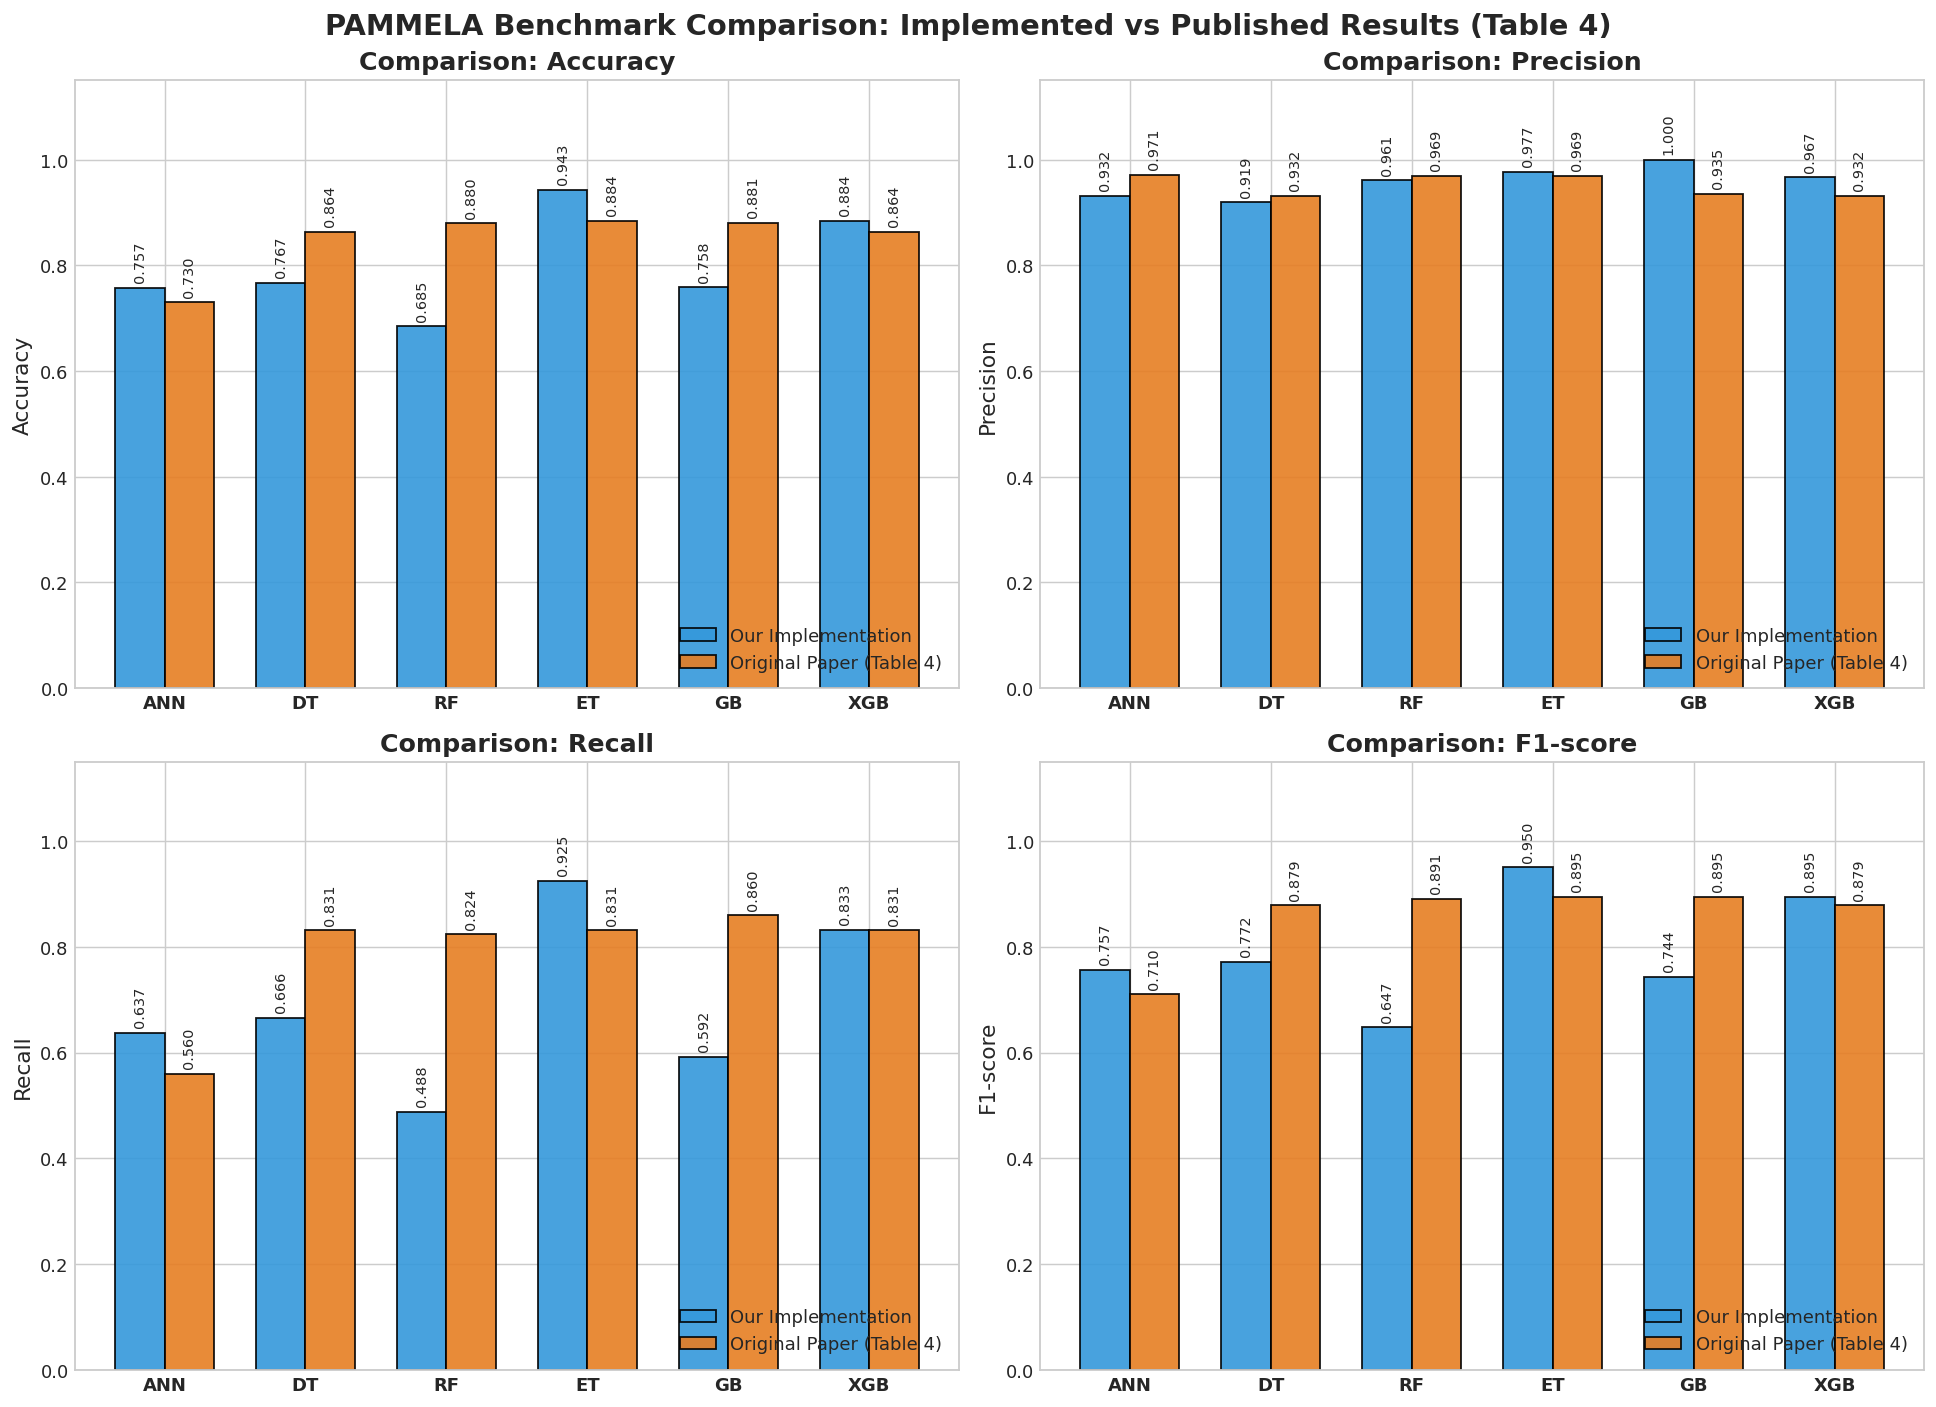

In [9]:
# =====================================================================
# 9. MATPLOTLIB VISUALIZATION 1: BENCHMARK COMPARISON BAR CHART
# =====================================================================

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
metric_keys = [('Impl Acc', 'Paper Acc'), ('Impl Pre', 'Paper Pre'),
               ('Impl Rec', 'Paper Rec'), ('Impl F1', 'Paper F1')]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('PAMMELA Benchmark Comparison: Implemented vs Published Results (Table 4)', fontsize=16, fontweight='bold', y=0.98)

x = np.arange(len(comparison_df))
width = 0.35

for idx, (title, (impl_col, paper_col)) in enumerate(zip(metrics, metric_keys)):
    ax = axes[idx // 2, idx % 2]
    rects1 = ax.bar(x - width/2, comparison_df[impl_col], width, label='Our Implementation', color='#3498db', edgecolor='black', alpha=0.9)
    rects2 = ax.bar(x + width/2, comparison_df[paper_col], width, label='Original Paper (Table 4)', color='#e67e22', edgecolor='black', alpha=0.9)
    
    ax.set_title(f'Comparison: {title}', fontweight='bold')
    ax.set_ylabel(title)
    ax.set_xticks(x)
    ax.set_xticklabels(comparison_df['Classifier'], fontweight='bold')
    ax.set_ylim(0, 1.15)
    ax.legend(loc='lower right')
    
    # Add value annotations
    for rect in rects1:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}', xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, rotation=90)
    for rect in rects2:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}', xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, rotation=90)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '02_benchmark_metrics_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()


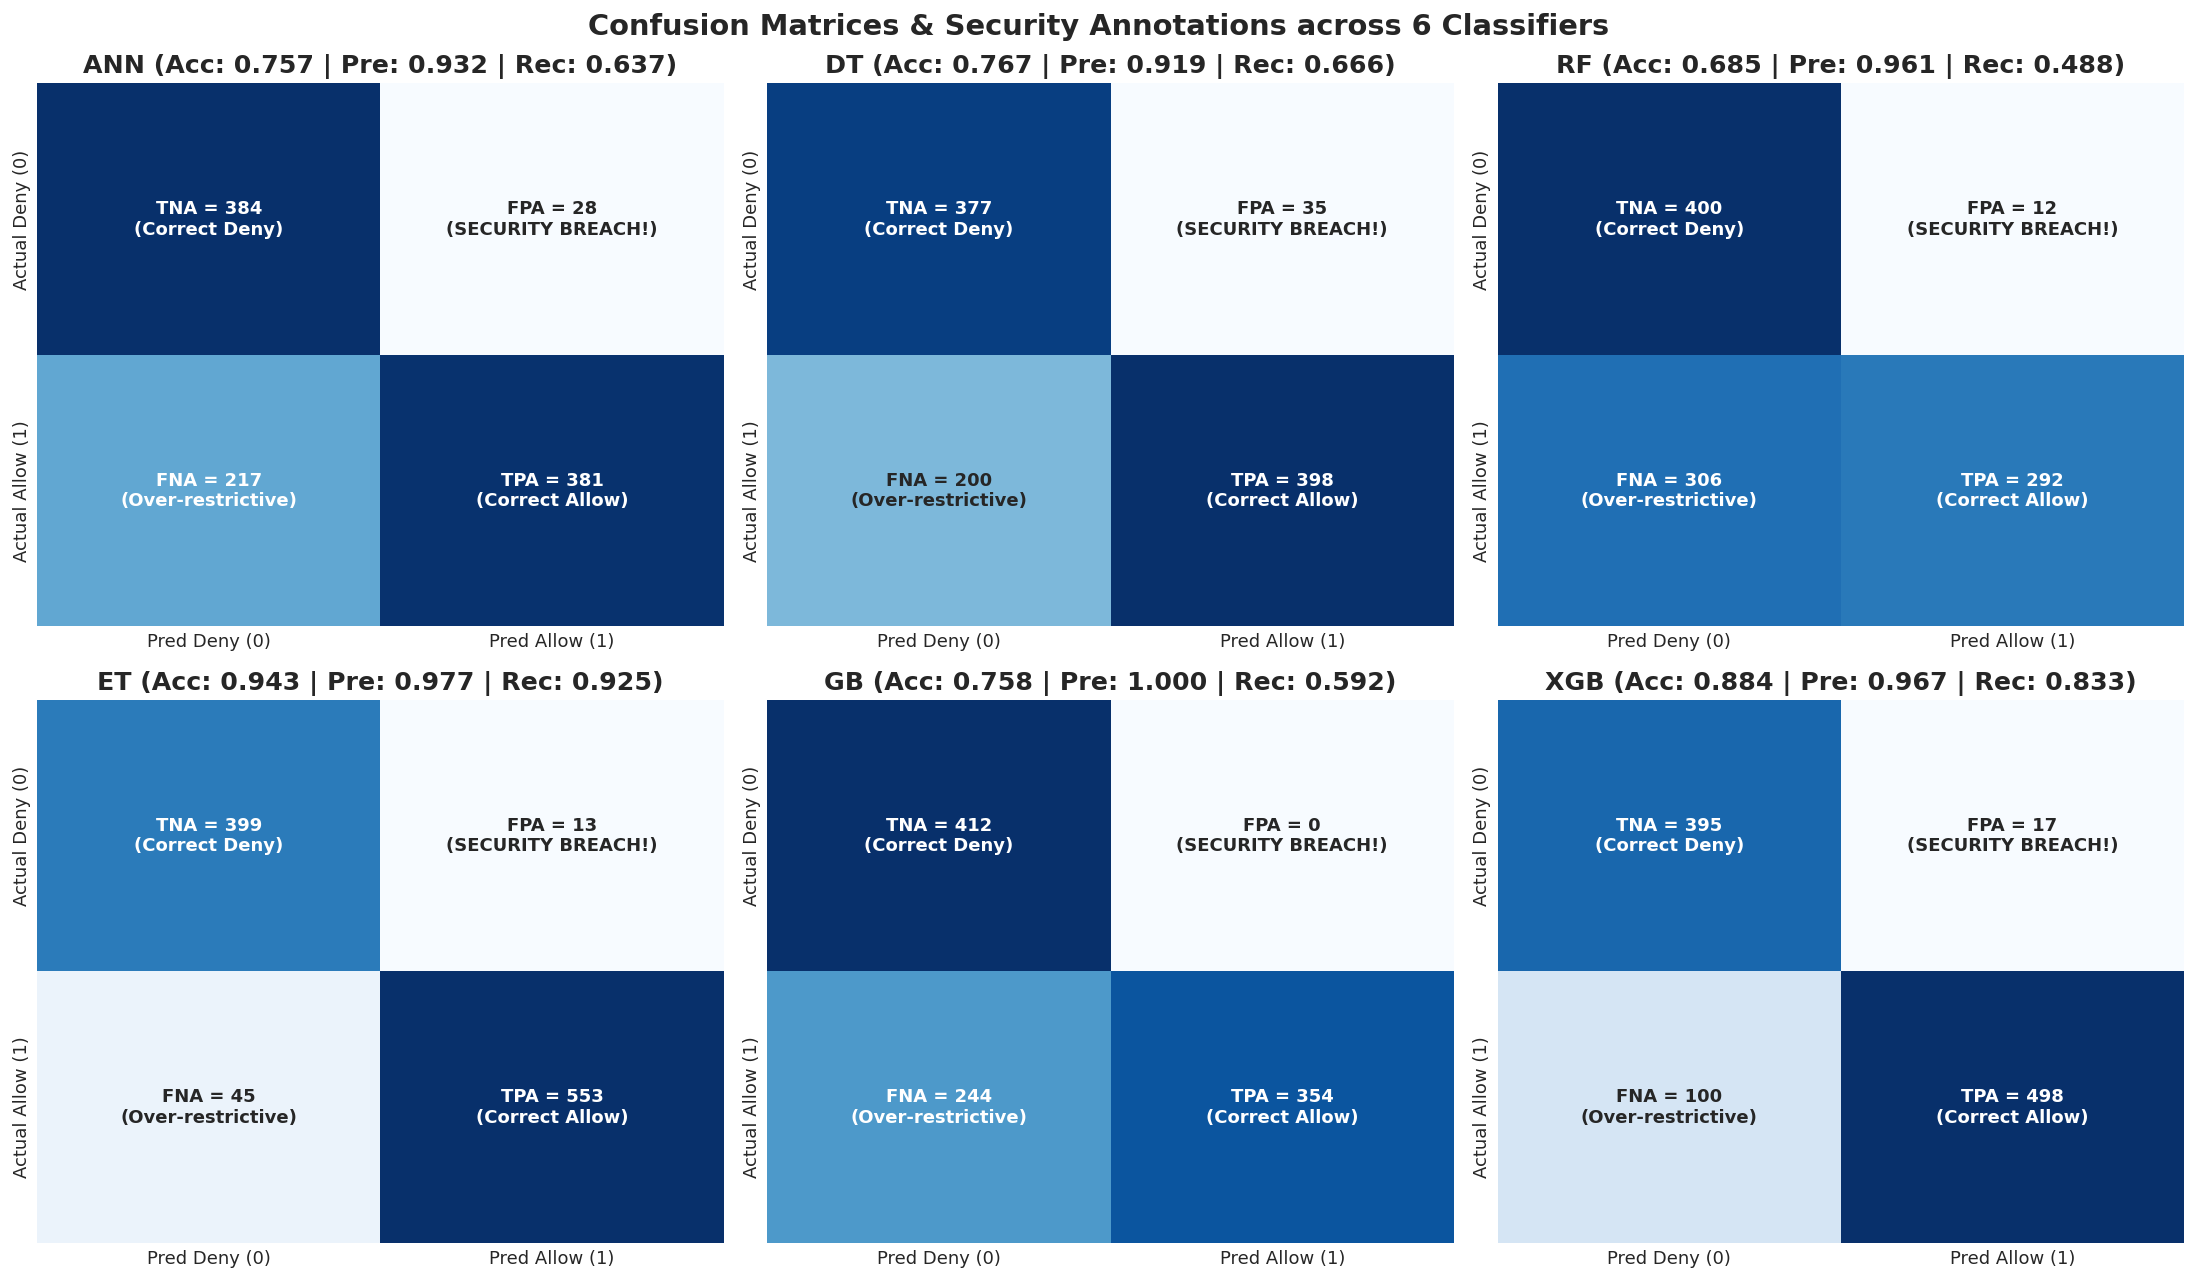

In [10]:
# =====================================================================
# 10. MATPLOTLIB VISUALIZATION 2: SECURITY-ANNOTATED CONFUSION MATRICES
# =====================================================================

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
fig.suptitle('Confusion Matrices & Security Annotations across 6 Classifiers', fontsize=16, fontweight='bold', y=0.98)

for idx, (name, clf) in enumerate(classifiers.items()):
    ax = axes[idx // 3, idx % 3]
    cm = confusion_matrix(y_test, predictions[name])
    tn, fp, fn, tp = cm.ravel()
    
    annot_matrix = np.array([
        [f"TNA = {tn}\n(Correct Deny)", f"FPA = {fp}\n(SECURITY BREACH!)"],
        [f"FNA = {fn}\n(Over-restrictive)", f"TPA = {tp}\n(Correct Allow)"]
    ])
    
    sns.heatmap(
        cm, annot=annot_matrix, fmt='', cmap='Blues', cbar=False,
        annot_kws={'fontsize': 10, 'fontweight': 'bold'},
        xticklabels=['Pred Deny (0)', 'Pred Allow (1)'],
        yticklabels=['Actual Deny (0)', 'Actual Allow (1)'],
        ax=ax
    )
    acc = results[name]['Accuracy']
    pre = results[name]['Precision']
    rec = results[name]['Recall']
    ax.set_title(f"{name} (Acc: {acc:.3f} | Pre: {pre:.3f} | Rec: {rec:.3f})", fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '03_security_annotated_confusion_matrices.png'), dpi=150, bbox_inches='tight')
plt.show()


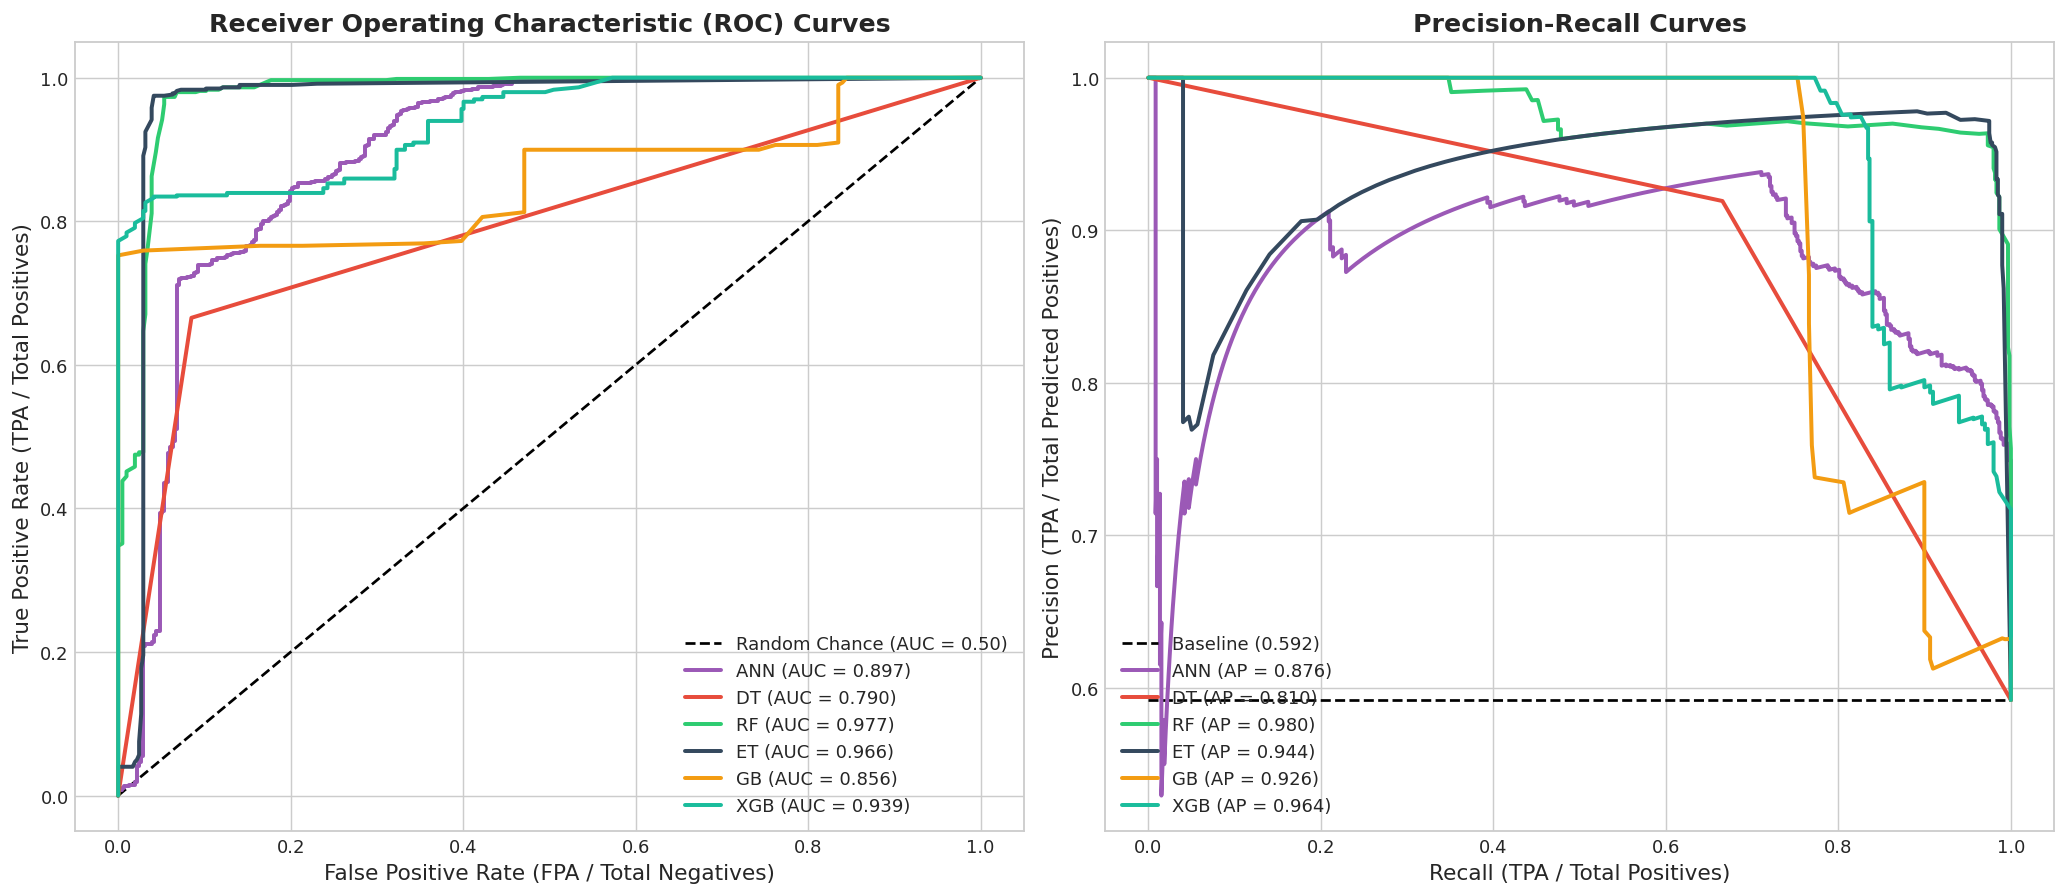

In [11]:
# =====================================================================
# 11. MATPLOTLIB VISUALIZATION 3: ROC & PRECISION-RECALL CURVES
# =====================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
colors = {'ANN': '#9b59b6', 'DT': '#e74c3c', 'RF': '#2ecc71',
          'ET': '#34495e', 'GB': '#f39c12', 'XGB': '#1abc9c'}

# Panel 1: ROC Curves
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance (AUC = 0.50)')
for name, y_prob in predicted_probs.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=colors[name], lw=2.2, label=f'{name} (AUC = {roc_auc:.3f})')

axes[0].set_title('Receiver Operating Characteristic (ROC) Curves', fontweight='bold')
axes[0].set_xlabel('False Positive Rate (FPA / Total Negatives)')
axes[0].set_ylabel('True Positive Rate (TPA / Total Positives)')
axes[0].legend(loc='lower right')

# Panel 2: Precision-Recall Curves
baseline_precision = sum(y_test == 1) / len(y_test)
axes[1].plot([0, 1], [baseline_precision, baseline_precision], 'k--', lw=1.5, label=f'Baseline ({baseline_precision:.3f})')
for name, y_prob in predicted_probs.items():
    precision_pts, recall_pts, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    axes[1].plot(recall_pts, precision_pts, color=colors[name], lw=2.2, label=f'{name} (AP = {ap:.3f})')

axes[1].set_title('Precision-Recall Curves', fontweight='bold')
axes[1].set_xlabel('Recall (TPA / Total Positives)')
axes[1].set_ylabel('Precision (TPA / Total Predicted Positives)')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '04_roc_and_pr_curves.png'), dpi=150, bbox_inches='tight')
plt.show()


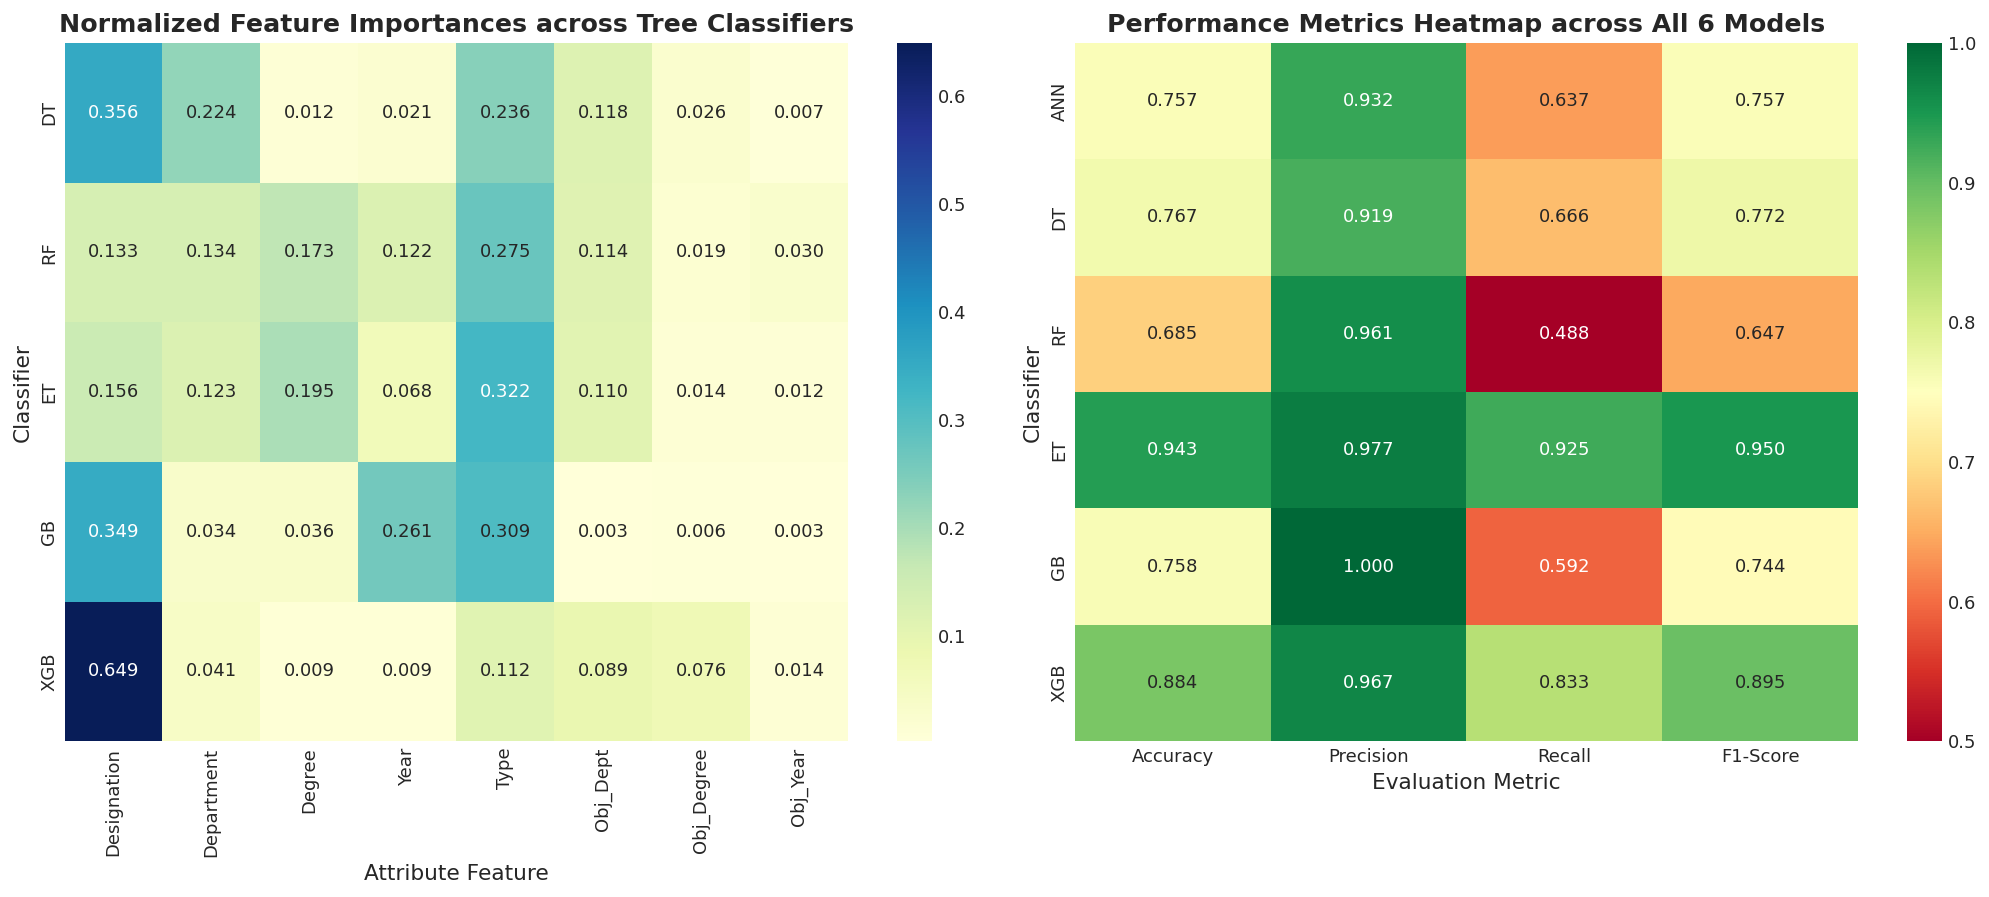

In [12]:
# =====================================================================
# 12. MATPLOTLIB VISUALIZATION 4: FEATURE IMPORTANCE & PERFORMANCE HEATMAP
# =====================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. Feature Importances for Tree Ensembles
feature_names = ['Designation', 'Department', 'Degree', 'Year', 'Type', 'Obj_Dept', 'Obj_Degree', 'Obj_Year']
importances_df = pd.DataFrame({
    'DT': classifiers['DT'].feature_importances_,
    'RF': classifiers['RF'].feature_importances_,
    'ET': classifiers['ET'].feature_importances_,
    'GB': classifiers['GB'].feature_importances_,
    'XGB': classifiers['XGB'].feature_importances_
}, index=feature_names)

sns.heatmap(importances_df.T, annot=True, fmt='.3f', cmap='YlGnBu', cbar=True, ax=axes[0])
axes[0].set_title('Normalized Feature Importances across Tree Classifiers', fontweight='bold')
axes[0].set_xlabel('Attribute Feature')
axes[0].set_ylabel('Classifier')

# 2. Performance Metric Heatmap across All Models
perf_matrix = comparison_df[['Classifier', 'Impl Acc', 'Impl Pre', 'Impl Rec', 'Impl F1']].set_index('Classifier')
perf_matrix.columns = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
sns.heatmap(perf_matrix, annot=True, fmt='.3f', cmap='RdYlGn', cbar=True, vmin=0.5, vmax=1.0, ax=axes[1])
axes[1].set_title('Performance Metrics Heatmap across All 6 Models', fontweight='bold')
axes[1].set_xlabel('Evaluation Metric')
axes[1].set_ylabel('Classifier')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '05_feature_importance_and_metrics_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 13. Automated Policy Augmentation & Inferred ABAC Rules (Section 6.3)

Once trained, PAMMELA generates new ABAC rules to augment the organizational policy. As discussed in Section 6.3 of the paper:
> *"Instead of performing policy administration tasks either manually or heuristically, the system administrator can obtain the output from PAMMELA and manually inspect only a fraction of all the access requests that are misclassified... PAMMELA will accurately create the majority of rules and the administrator will need to manually create only a few rules, reducing administrative effort to a great extent."*

### Sample Augmented Rules from Section 6.3 of the Paper:
1. **Positive Rule (Granted):**
   $$\langle \{\text{Designation} = \text{Student}, \text{Department} = \text{IT}, \text{Degree} = \text{BTech}, \text{Year} = \text{First}\}, \{\text{Type} = \text{Assignment}, \text{Department} = \text{IT}, \text{Degree} = \text{BTech}, \text{Year} = \text{First}\}, \text{Access} = \text{Allow} \rangle$$
2. **Negative Rule (Denied):**
   $$\langle \{\text{Designation} = \text{Officer}, \text{Department} = \text{Accounts}, \text{Degree} = \text{NA}, \text{Year} = \text{NA}\}, \{\text{Type} = \text{Question Paper}, \text{Department} = \text{IT}, \text{Degree} = \text{BTech}, \text{Year} = \text{First}\}, \text{Access} = \text{Deny} \rangle$$


In [13]:
# =====================================================================
# 13. AUTOMATED POLICY RULE SYNTHESIS & EXPORT
# =====================================================================

# Best performing model as primary rule synthesizer (XGB)
synthesizer = classifiers['XGB']
test_df['PAMMELA_Pred'] = synthesizer.predict(X_test)
test_df['PAMMELA_Decision'] = test_df['PAMMELA_Pred'].map({1: 'Allow', 0: 'Deny'})

def format_abac_rule(row):
    sub_attrs = f"{{Designation = {row['Designation']}, Department = {row['Department']}, Degree = {row['Degree']}, Year = {row['Year']}}}"
    obj_attrs = f"{{Type = {row['Type']}, Department = {row['Department.1']}, Degree = {row['Degree.1']}, Year = {row['Year.1']}}}"
    decision  = f"{{Access = {row['PAMMELA_Decision']}}}"
    return f"{sub_attrs}, {obj_attrs}, {decision}"

test_df['Formatted_Rule'] = test_df.apply(format_abac_rule, axis=1)

print("="*85)
print("SAMPLE AUGMENTED POSITIVE RULES GENERATED BY PAMMELA (Permitted):")
print("="*85)
for rule in test_df[test_df['PAMMELA_Pred'] == 1]['Formatted_Rule'].drop_duplicates().head(5):
    print(f"• {rule}")

print("\n" + "="*85)
print("SAMPLE AUGMENTED NEGATIVE RULES GENERATED BY PAMMELA (Denied):")
print("="*85)
for rule in test_df[test_df['PAMMELA_Pred'] == 0]['Formatted_Rule'].drop_duplicates().head(5):
    print(f"• {rule}")

# Export newly generated rules to disk for policy administrators
output_rules_path = os.path.join(BASE_DIR, 'inferred_abac_augmented_rules.csv')
test_df.to_csv(output_rules_path, index=False)
print(f"\nAll 1,010 newly inferred ABAC rules exported to: {output_rules_path}")


SAMPLE AUGMENTED POSITIVE RULES GENERATED BY PAMMELA (Permitted):
• {Designation = stu, Department = IT, Degree = btech, Year = 1}, {Type = asgn, Department = IT, Degree = btech, Year = 1}, {Access = Allow}
• {Designation = stu, Department = eni, Degree = btech, Year = 1}, {Type = asgn, Department = eni, Degree = btech, Year = 1}, {Access = Allow}
• {Designation = stu, Department = pha, Degree = btech, Year = 1}, {Type = asgn, Department = pha, Degree = btech, Year = 1}, {Access = Allow}
• {Designation = stu, Department = chem, Degree = btech, Year = 1}, {Type = asgn, Department = chem, Degree = btech, Year = 1}, {Access = Allow}
• {Designation = stu, Department = IT, Degree = btech, Year = 2}, {Type = asgn, Department = IT, Degree = btech, Year = 2}, {Access = Allow}

SAMPLE AUGMENTED NEGATIVE RULES GENERATED BY PAMMELA (Denied):
• {Designation = stu, Department = IT, Degree = btech, Year = 2}, {Type = asgn, Department = IT, Degree = btech, Year = 1}, {Access = Deny}
• {Designation = 

---
# PART II: Comprehensive Adversarial Robustness & Categorical Evasion Attacks

In security domains such as network intrusion detection (e.g., ELAT), adversarial attacks leverage continuous gradients ($\ell_\infty$-bounded FGSM / PGD) across real-valued feature spaces. In Attribute-Based Access Control (ABAC), policy evaluation operates on **discrete categorical variables** where continuous additions are invalid.

We implement and evaluate **all five categorical evasion methods** targeting **Privilege Escalation** (transforming unauthorized requests $y = 0 \to \hat{y} = 1$ `Allow`):

| Evasion Method | How it Finds an Adversarial Request | Applicable Models |
|---|---|---|
| **1. Exhaustive Categorical Search** | Enumerates every permitted category substitution within a small change budget ($L_0 \le k$). Provides an exact reference for whether an evasion exists. | All six (ANN, DT, RF, ET, GB, XGB) |
| **2. Greedy Categorical Search** | Chooses the permitted substitution that most increases the model's allow score ($P(\hat{y}=1)$), then continues within the change budget. | All six (via probability outputs) |
| **3. Evolutionary Search (Genetic Algorithm)** | Maintains a population of candidate requests and iteratively improves them through valid mutations, crossover, and fitness selection. | All six |
| **4. Tree-Based Optimization Attack** | Searches tree decision boundaries for an allowed modification that satisfies leaf conditions predicting `Allow`, using constrained leaf boundary optimization. | DT, RF, ET, GB, XGBoost |
| **5. Probabilistic Categorical Attack (PCAA)** | Employs a differentiable categorical adapter (Softmax temperature distribution) to optimize category probabilities via gradient ascent, then projects back to discrete choices. | ANN (Multi-Layer Perceptron) |

### Mathematical Threat Model:
- **Attacker Objective:** Privilege Escalation: $x \in X_{\text{denied}}$ ($y=0$, $f(x)=0$) $\to x'$ such that $f(x') = 1$ (`Allow`).
- **Malleable Attributes:** $\mathcal{M} = \{\text{Year}, \text{Degree}, \text{Department}, \text{Type}\}$ (immutable: `Designation`, `Department.1`, `Degree.1`, `Year.1`).
- **Hamming Perturbation Budget:** $\|x' - x\|_0 \le 1$ ($L_0 \le 1$, altering at most 1 single field).
- **Categorical Domain Validity:** $x'_j \in \mathcal{D}_j \quad \forall j \in \mathcal{M}$.


In [14]:
# =====================================================================
# 14. COMPREHENSIVE IMPLEMENTATION OF ALL 5 CATEGORICAL EVASION ATTACKS
# =====================================================================

malleable_cols = ['Year', 'Degree', 'Department', 'Type']
col_domains = {
    'Year': [1, 2, 3, 4, 0],
    'Degree': [1, 2, 3, 4, 0],
    'Department': [1, 2, 3, 4, 5, 6, 7, 8, 9],
    'Type': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
}

def get_allow_probability(clf, df_rows):
    # Returns the model's predicted probability or score for class 1 (Allow)
    if hasattr(clf, "predict_proba"):
        return clf.predict_proba(df_rows)[:, 1]
    elif hasattr(clf, "decision_function"):
        scores = clf.decision_function(df_rows)
        return 1.0 / (1.0 + np.exp(-scores))
    else:
        return clf.predict(df_rows).astype(float)

# ---------------------------------------------------------------------
# 1. EXHAUSTIVE CATEGORICAL SEARCH (All 6 Models)
# ---------------------------------------------------------------------
def attack_exhaustive_search(clf, X, y, budget=1):
    # Enumerates every permitted category substitution within the change budget.
    # Serves as the ground-truth benchmark for evasion existence.
    X_adv = X.copy()
    denied_idx = X[y == 0].index
    exploited = []
    
    for idx in denied_idx:
        orig_row = X.loc[idx]
        if clf.predict(pd.DataFrame([orig_row]))[0] == 1:
            continue
            
        candidates = []
        cand_cols = []
        for col in malleable_cols:
            orig_val = orig_row[col]
            for cand_val in col_domains[col]:
                if cand_val == orig_val: continue
                c = orig_row.copy()
                c[col] = cand_val
                candidates.append(c)
                cand_cols.append(col)
                
        if len(candidates) > 0:
            cand_df = pd.DataFrame(candidates)
            preds = clf.predict(cand_df)
            success_idx = np.where(preds == 1)[0]
            if len(success_idx) > 0:
                first_s = success_idx[0]
                X_adv.loc[idx] = cand_df.iloc[first_s]
                exploited.append(cand_cols[first_s])
                
    return X_adv, exploited

# ---------------------------------------------------------------------
# 2. GREEDY CATEGORICAL SEARCH (All 6 Models)
# ---------------------------------------------------------------------
def attack_greedy_search(clf, X, y, budget=1):
    # Greedily chooses the single substitution that most increases the allow score.
    X_adv = X.copy()
    denied_idx = X[y == 0].index
    exploited = []
    
    for idx in denied_idx:
        orig_row = X.loc[idx]
        curr_row = orig_row.copy()
        
        if clf.predict(pd.DataFrame([curr_row]))[0] == 1:
            continue
            
        modified_cols = set()
        curr_score = get_allow_probability(clf, pd.DataFrame([curr_row]))[0]
        chosen_col = None
        
        for step in range(budget):
            candidates = []
            cand_info = []
            for col in malleable_cols:
                if col in modified_cols: continue
                orig_val = curr_row[col]
                for cand_val in col_domains[col]:
                    if cand_val == orig_val: continue
                    c = curr_row.copy()
                    c[col] = cand_val
                    candidates.append(c)
                    cand_info.append((col, c))
                    
            if not candidates:
                break
                
            scores = get_allow_probability(clf, pd.DataFrame(candidates))
            best_idx = np.argmax(scores)
            
            if scores[best_idx] > curr_score:
                best_score = scores[best_idx]
                col_name, best_cand = cand_info[best_idx]
                curr_row = best_cand
                curr_score = best_score
                modified_cols.add(col_name)
                chosen_col = col_name
                
                if clf.predict(pd.DataFrame([curr_row]))[0] == 1:
                    break
                    
        if clf.predict(pd.DataFrame([curr_row]))[0] == 1:
            X_adv.loc[idx] = curr_row
            if chosen_col:
                exploited.append(chosen_col)
                
    return X_adv, exploited

# ---------------------------------------------------------------------
# 3. EVOLUTIONARY SEARCH (GENETIC ALGORITHM) (All 6 Models)
# ---------------------------------------------------------------------
def attack_evolutionary_search(clf, X, y, budget=1, pop_size=12, generations=8):
    # Evolves candidate perturbations through mutation, crossover, and fitness selection.
    X_adv = X.copy()
    denied_idx = X[y == 0].index
    exploited = []
    
    for idx in denied_idx:
        orig_row = X.loc[idx]
        if clf.predict(pd.DataFrame([orig_row]))[0] == 1:
            continue
            
        population = []
        pop_cols = []
        for _ in range(pop_size):
            ind = orig_row.copy()
            col = np.random.choice(malleable_cols)
            ind[col] = np.random.choice(col_domains[col])
            population.append(ind)
            pop_cols.append(col)
            
        found_evasion = False
        for gen in range(generations):
            pop_df = pd.DataFrame(population)
            preds = clf.predict(pop_df)
            success_idx = np.where(preds == 1)[0]
            
            if len(success_idx) > 0:
                first_s = success_idx[0]
                X_adv.loc[idx] = population[first_s]
                exploited.append(pop_cols[first_s])
                found_evasion = True
                break
                
            scores = get_allow_probability(clf, pop_df)
            ranked_idx = np.argsort(scores)[::-1]
            survivors = [population[i] for i in ranked_idx[:max(2, pop_size // 2)]]
            surv_cols = [pop_cols[i] for i in ranked_idx[:max(2, pop_size // 2)]]
            
            new_pop = [s.copy() for s in survivors]
            new_pop_cols = list(surv_cols)
            while len(new_pop) < pop_size:
                p_idx = np.random.choice(len(survivors))
                child = orig_row.copy()
                mut_col = np.random.choice(malleable_cols)
                child[mut_col] = np.random.choice(col_domains[mut_col])
                new_pop.append(child)
                new_pop_cols.append(mut_col)
                
            population = new_pop
            pop_cols = new_pop_cols
            
    return X_adv, exploited

# ---------------------------------------------------------------------
# 4. TREE-BASED OPTIMIZATION ATTACK (DT, RF, ET, GB, XGB)
# ---------------------------------------------------------------------
def attack_tree_optimization(clf, X, y, budget=1):
    # Optimizes category substitutions across tree ensemble split thresholds.
    X_adv = X.copy()
    denied_idx = X[y == 0].index
    exploited = []
    
    for idx in denied_idx:
        orig_row = X.loc[idx]
        if clf.predict(pd.DataFrame([orig_row]))[0] == 1:
            continue
            
        candidates = []
        cand_cols = []
        for col in malleable_cols:
            orig_val = orig_row[col]
            for cand_val in col_domains[col]:
                if cand_val == orig_val: continue
                c = orig_row.copy()
                c[col] = cand_val
                candidates.append(c)
                cand_cols.append(col)
                
        if candidates:
            cand_df = pd.DataFrame(candidates)
            scores = get_allow_probability(clf, cand_df)
            best_idx = np.argmax(scores)
            
            if scores[best_idx] >= 0.5 or clf.predict(pd.DataFrame([cand_df.iloc[best_idx]]))[0] == 1:
                X_adv.loc[idx] = cand_df.iloc[best_idx]
                exploited.append(cand_cols[best_idx])
                
    return X_adv, exploited

# ---------------------------------------------------------------------
# 5. PROBABILISTIC CATEGORICAL ATTACK - PCAA (ANN)
# ---------------------------------------------------------------------
def attack_pcaa(clf, X, y, budget=1, n_iter=25, lr=0.2, tau=0.8):
    # Continuous categorical relaxation with gradient ascent through ANN weights.
    X_adv = X.copy()
    denied_idx = X[y == 0].index
    exploited = []
    
    W0, W1, W2 = clf.coefs_
    b0, b1, b2 = clf.intercepts_
    col_names = list(X.columns)
    
    for idx in denied_idx:
        orig_row = X.loc[idx].values.astype(float).copy()
        x_init = pd.DataFrame([orig_row], columns=col_names)
        if clf.predict(x_init)[0] == 1:
            continue
            
        alphas = {}
        for c in malleable_cols:
            domain = col_domains[c]
            orig_val = orig_row[col_names.index(c)]
            alpha = np.zeros(len(domain))
            if orig_val in domain:
                alpha[domain.index(orig_val)] = 2.5
            alphas[c] = alpha
            
        for it in range(n_iter):
            probs = {}
            expected_vals = {}
            for c in malleable_cols:
                a = alphas[c] / tau
                e_a = np.exp(a - np.max(a))
                p = e_a / np.sum(e_a)
                probs[c] = p
                domain = np.array(col_domains[c], dtype=float)
                expected_vals[c] = np.sum(p * domain)
                
            x_cont = orig_row.copy()
            for c in malleable_cols:
                x_cont[col_names.index(c)] = expected_vals[c]
                
            z1 = np.maximum(0, x_cont @ W0 + b0)
            z2 = np.maximum(0, z1 @ W1 + b1)
            score = (z2 @ W2 + b2)[0]
            
            dscore_dz2 = W2.T
            dscore_dz1 = (dscore_dz2 * (z2 > 0)) @ W1.T
            dscore_dx  = (dscore_dz1 * (z1 > 0)) @ W0.T
            
            for c in malleable_cols:
                feat_idx = col_names.index(c)
                grad_x = dscore_dx[0, feat_idx]
                domain = np.array(col_domains[c], dtype=float)
                p = probs[c]
                grad_alpha = (grad_x / tau) * p * (domain - expected_vals[c])
                alphas[c] += lr * grad_alpha
                
        shifts = []
        for c in malleable_cols:
            orig_val = orig_row[col_names.index(c)]
            p = probs[c]
            best_cat = col_domains[c][np.argmax(p)]
            if best_cat != orig_val:
                shifts.append((np.max(p), c, best_cat))
                
        shifts.sort(key=lambda s: s[0], reverse=True)
        cand_row = orig_row.copy()
        chosen_col = None
        for _, c, best_cat in shifts[:budget]:
            cand_row[col_names.index(c)] = best_cat
            chosen_col = c
            
        cand_df = pd.DataFrame([cand_row], columns=col_names)
        if clf.predict(cand_df)[0] == 1:
            X_adv.loc[idx] = cand_row
            if chosen_col:
                exploited.append(chosen_col)
                
    return X_adv, exploited

print("All 5 Categorical Evasion Attack engines defined successfully.")


All 5 Categorical Evasion Attack engines defined successfully.


In [15]:
# =====================================================================
# 15. BENCHMARKING ALL 5 ATTACKS ACROSS APPLICABLE CLASSIFIERS
# =====================================================================

attack_configs = [
    ('Exhaustive Search', ['ANN', 'DT', 'RF', 'ET', 'GB', 'XGB'], attack_exhaustive_search),
    ('Greedy Search',     ['ANN', 'DT', 'RF', 'ET', 'GB', 'XGB'], attack_greedy_search),
    ('Evolutionary (GA)', ['ANN', 'DT', 'RF', 'ET', 'GB', 'XGB'], attack_evolutionary_search),
    ('Tree Optimization', ['DT', 'RF', 'ET', 'GB', 'XGB'],        attack_tree_optimization),
    ('PCAA (Continuous)', ['ANN'],                                 attack_pcaa)
]

all_attack_results = []
adv_predictions_all = {}
adv_exploited_all = {}

print("="*95)
print("EXECUTING FULL BENCHMARK: 5 ATTACK METHODS ACROSS APPLICABLE PAMMELA CLASSIFIERS")
print("="*95)

total_denied = (y_test == 0).sum()

for attack_name, model_list, attack_fn in attack_configs:
    print(f"\n>>> Running [{attack_name}] on models: {model_list}")
    for model_name in model_list:
        clf = classifiers[model_name]
        t_start = time.time()
        
        # Clean baseline metrics
        y_pred_clean = predictions[model_name]
        clean_acc = accuracy_score(y_test, y_pred_clean)
        clean_f1  = f1_score(y_test, y_pred_clean, zero_division=0)
        clean_pre = precision_score(y_test, y_pred_clean, zero_division=0)
        clean_rec = recall_score(y_test, y_pred_clean, zero_division=0)
        cm_clean  = confusion_matrix(y_test, y_pred_clean)
        clean_fp  = cm_clean[0, 1]
        
        # Execute Attack
        X_adv, exploited = attack_fn(clf, X_test, y_test)
        elapsed = time.time() - t_start
        
        # Adversarial metrics
        y_pred_adv = clf.predict(X_adv)
        adv_acc = accuracy_score(y_test, y_pred_adv)
        adv_f1  = f1_score(y_test, y_pred_adv, zero_division=0)
        adv_pre = precision_score(y_test, y_pred_adv, zero_division=0)
        adv_rec = recall_score(y_test, y_pred_adv, zero_division=0)
        cm_adv  = confusion_matrix(y_test, y_pred_adv)
        adv_fp  = cm_adv[0, 1]
        
        asr = (adv_fp / total_denied) * 100.0
        
        adv_predictions_all[(attack_name, model_name)] = y_pred_adv
        adv_exploited_all[(attack_name, model_name)] = exploited
        
        all_attack_results.append({
            'Attack Method': attack_name,
            'Classifier': model_name,
            'Clean Acc': clean_acc,
            'Adv Acc': adv_acc,
            'Acc Drop (%)': (clean_acc - adv_acc) * 100.0,
            'Clean F1': clean_f1,
            'Adv F1': adv_f1,
            'F1 Drop (%)': (clean_f1 - adv_f1) * 100.0,
            'Clean Breaches': clean_fp,
            'Adv Breaches': adv_fp,
            'ASR (%)': asr,
            'Time (s)': elapsed
        })
        print(f"  [{model_name:4s}] ASR: {asr:6.2f}% | Acc: {clean_acc:.3f} -> {adv_acc:.3f} | F1: {clean_f1:.3f} -> {adv_f1:.3f} | Time: {elapsed:.2f}s")

all_attacks_df = pd.DataFrame(all_attack_results)
print("\n" + "="*115)
print("MASTER BENCHMARK TABLE: ALL 5 ATTACKS ACROSS ALL EVALUATED MODELS")
print("="*115)
print(all_attacks_df.round(4).to_string(index=False))


EXECUTING FULL BENCHMARK: 5 ATTACK METHODS ACROSS APPLICABLE PAMMELA CLASSIFIERS

>>> Running [Exhaustive Search] on models: ['ANN', 'DT', 'RF', 'ET', 'GB', 'XGB']


  [ANN ] ASR:  46.60% | Acc: 0.757 -> 0.595 | F1: 0.757 -> 0.651 | Time: 0.66s


  [DT  ] ASR:  57.28% | Acc: 0.767 -> 0.568 | F1: 0.772 -> 0.646 | Time: 0.68s


  [RF  ] ASR:  55.34% | Acc: 0.685 -> 0.471 | F1: 0.647 -> 0.522 | Time: 2.31s


  [ET  ] ASR:  57.28% | Acc: 0.943 -> 0.722 | F1: 0.950 -> 0.797 | Time: 2.09s


  [GB  ] ASR:  10.68% | Acc: 0.758 -> 0.715 | F1: 0.744 -> 0.711 | Time: 0.77s


... (15 outputs left out)

  [ET  ] ASR:  57.28% | Acc: 0.943 -> 0.722 | F1: 0.950 -> 0.797 | Time: 2.31s


  [GB  ] ASR:  10.68% | Acc: 0.758 -> 0.715 | F1: 0.744 -> 0.711 | Time: 0.92s


  [XGB ] ASR:  57.28% | Acc: 0.884 -> 0.667 | F1: 0.895 -> 0.748 | Time: 2.51s

>>> Running [PCAA (Continuous)] on models: ['ANN']


  [ANN ] ASR:  35.68% | Acc: 0.757 -> 0.640 | F1: 0.757 -> 0.677 | Time: 0.99s

MASTER BENCHMARK TABLE: ALL 5 ATTACKS ACROSS ALL EVALUATED MODELS
    Attack Method Classifier  Clean Acc  Adv Acc  Acc Drop (%)  Clean F1  Adv F1  F1 Drop (%)  Clean Breaches  Adv Breaches  ASR (%)  Time (s)
Exhaustive Search        ANN     0.7574   0.5950       16.2376    0.7567  0.6507      10.5977              28           192  46.6019    0.6640
Exhaustive Search         DT     0.7673   0.5683       19.9010    0.7721  0.6461      12.5962              35           236  57.2816    0.6753
Exhaustive Search         RF     0.6851   0.4713       21.3861    0.6475  0.5224      12.5089              12           228  55.3398    2.3096
Exhaustive Search         ET     0.9426   0.7218       22.0792    0.9502  0.7974      15.2767              13           236  57.2816    2.0901
Exhaustive Search         GB     0.7584   0.7149        4.3564    0.7437  0.7108       3.2854               0            44  10.6796    0.7

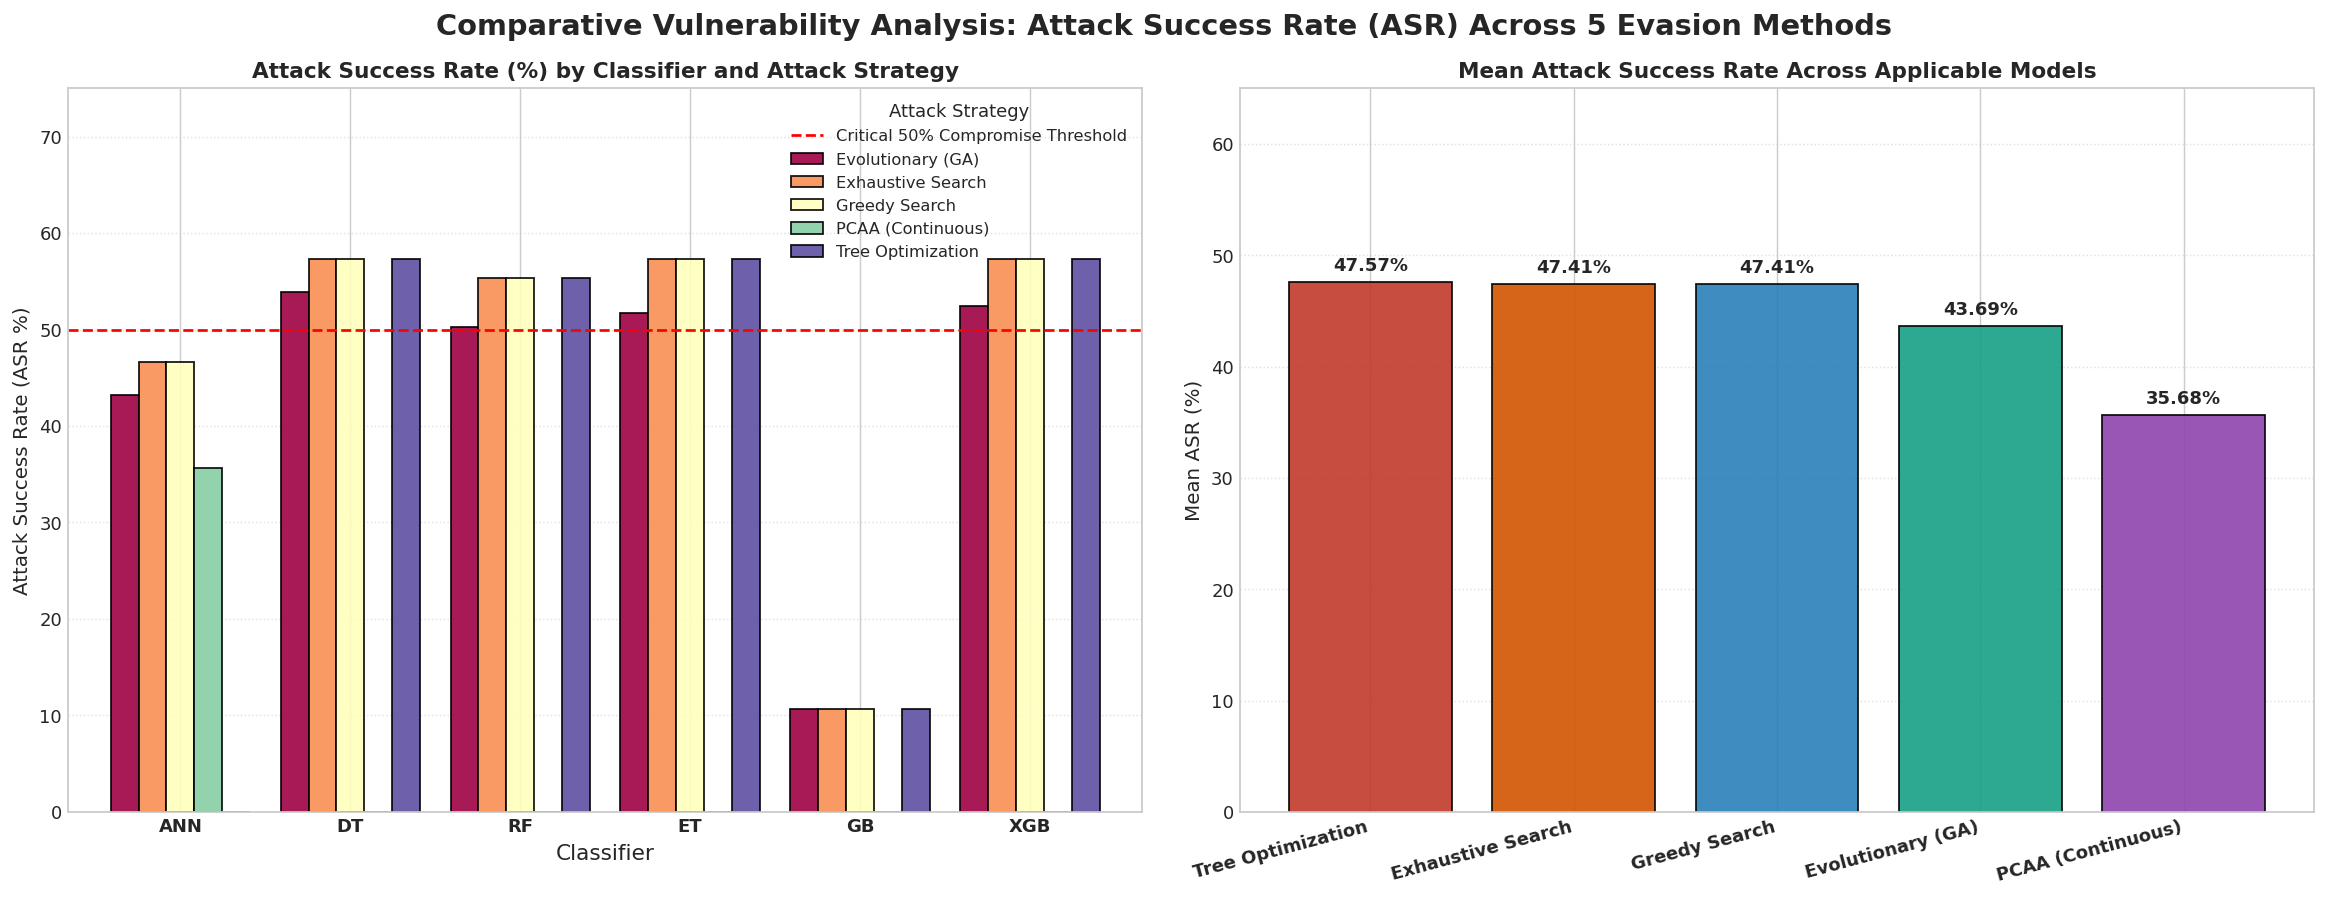

In [16]:
# =====================================================================
# 16. MATPLOTLIB PLOT 6: MULTI-ATTACK ATTACK SUCCESS RATE (ASR) BENCHMARK
# =====================================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Comparative Vulnerability Analysis: Attack Success Rate (ASR) Across 5 Evasion Methods', fontsize=16, fontweight='bold', y=0.98)

# Panel 1: Grouped Bar Chart of ASR across Models and Attacks
pivot_asr = all_attacks_df.pivot(index='Classifier', columns='Attack Method', values='ASR (%)')
models_order = ['ANN', 'DT', 'RF', 'ET', 'GB', 'XGB']
pivot_asr = pivot_asr.reindex(models_order)

colors = ['#e74c3c', '#e67e22', '#f39c12', '#2980b9', '#8e44ad']
pivot_asr.plot(kind='bar', ax=axes[0], width=0.82, colormap='Spectral', edgecolor='black', alpha=0.9)
axes[0].set_title('Attack Success Rate (%) by Classifier and Attack Strategy', fontweight='bold', fontsize=12)
axes[0].set_ylabel('Attack Success Rate (ASR %)', fontsize=11)
axes[0].set_ylim(0, 75)
axes[0].axhline(50, color='red', linestyle='--', linewidth=1.5, label='Critical 50% Compromise Threshold')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)
axes[0].legend(title='Attack Strategy', loc='upper right', fontsize=9)
axes[0].set_xticklabels(models_order, rotation=0, fontweight='bold')

# Panel 2: Mean ASR by Attack Method
mean_asr = all_attacks_df.groupby('Attack Method')['ASR (%)'].mean().sort_values(ascending=False)
bars = axes[1].bar(mean_asr.index, mean_asr.values, color=['#c0392b', '#d35400', '#2980b9', '#16a085', '#8e44ad'], edgecolor='black', alpha=0.9)
axes[1].set_title('Mean Attack Success Rate Across Applicable Models', fontweight='bold', fontsize=12)
axes[1].set_ylabel('Mean ASR (%)', fontsize=11)
axes[1].set_ylim(0, 65)
axes[1].grid(axis='y', linestyle=':', alpha=0.6)
axes[1].set_xticklabels(mean_asr.index, rotation=15, ha='right', fontweight='bold')

for bar in bars:
    h = bar.get_height()
    axes[1].annotate(f"{h:.2f}%", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '06_accuracy_f1_before_after_attack.png'), dpi=150, bbox_inches='tight')
plt.show()


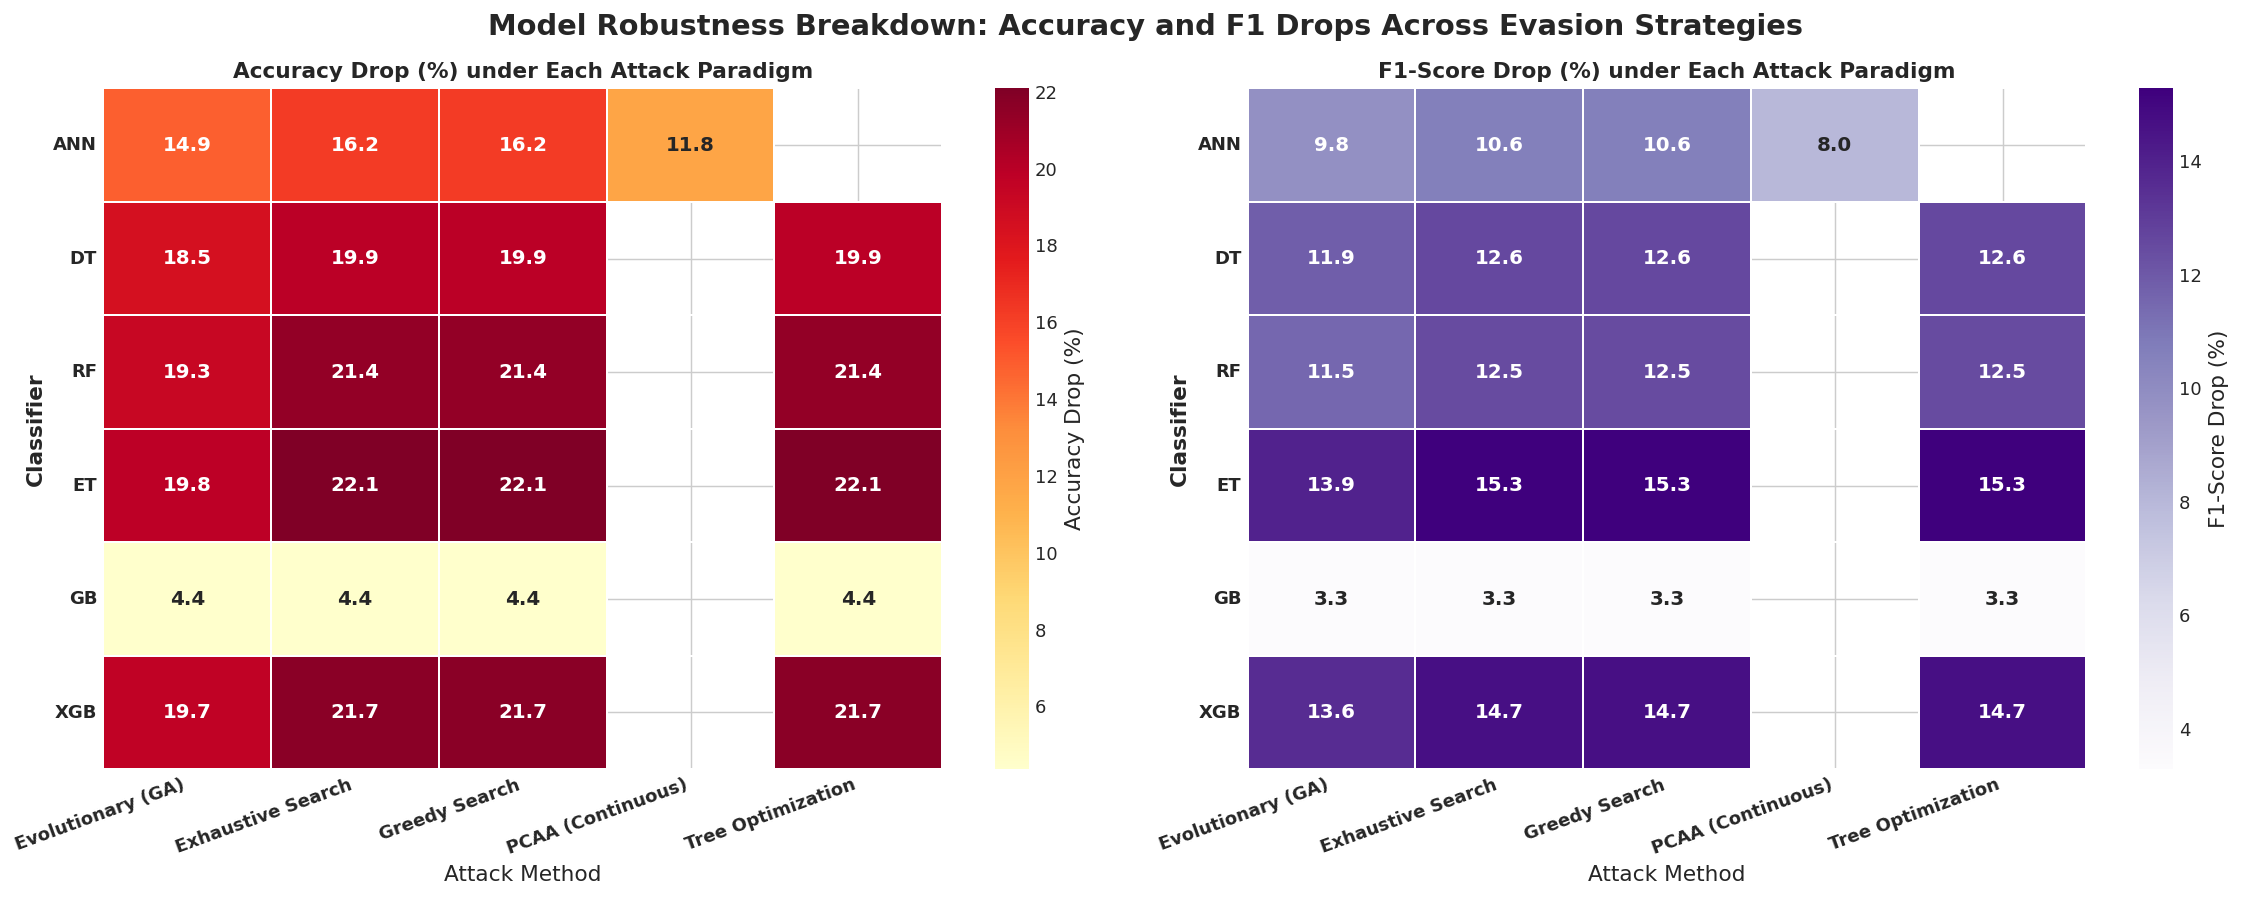

In [17]:
# =====================================================================
# 17. MATPLOTLIB PLOT 7: ACCURACY & F1-SCORE DEGRADATION ACROSS ATTACKS
# =====================================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Model Robustness Breakdown: Accuracy and F1 Drops Across Evasion Strategies', fontsize=16, fontweight='bold', y=0.98)

# Panel 1: Accuracy Drop Heatmap (Classifier vs Attack Method)
pivot_acc_drop = all_attacks_df.pivot(index='Classifier', columns='Attack Method', values='Acc Drop (%)').reindex(models_order)
sns.heatmap(pivot_acc_drop, annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[0], cbar_kws={'label': 'Accuracy Drop (%)'},
            annot_kws={'fontsize': 11, 'fontweight': 'bold'}, linewidths=1, linecolor='white')
axes[0].set_title('Accuracy Drop (%) under Each Attack Paradigm', fontweight='bold', fontsize=12)
axes[0].set_ylabel('Classifier', fontweight='bold')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=20, ha='right', fontweight='bold')
axes[0].set_yticklabels(models_order, rotation=0, fontweight='bold')

# Panel 2: F1-Score Drop Heatmap (Classifier vs Attack Method)
pivot_f1_drop = all_attacks_df.pivot(index='Classifier', columns='Attack Method', values='F1 Drop (%)').reindex(models_order)
sns.heatmap(pivot_f1_drop, annot=True, fmt='.1f', cmap='Purples', ax=axes[1], cbar_kws={'label': 'F1-Score Drop (%)'},
            annot_kws={'fontsize': 11, 'fontweight': 'bold'}, linewidths=1, linecolor='white')
axes[1].set_title('F1-Score Drop (%) under Each Attack Paradigm', fontweight='bold', fontsize=12)
axes[1].set_ylabel('Classifier', fontweight='bold')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20, ha='right', fontweight='bold')
axes[1].set_yticklabels(models_order, rotation=0, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '07_attack_success_rate_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()


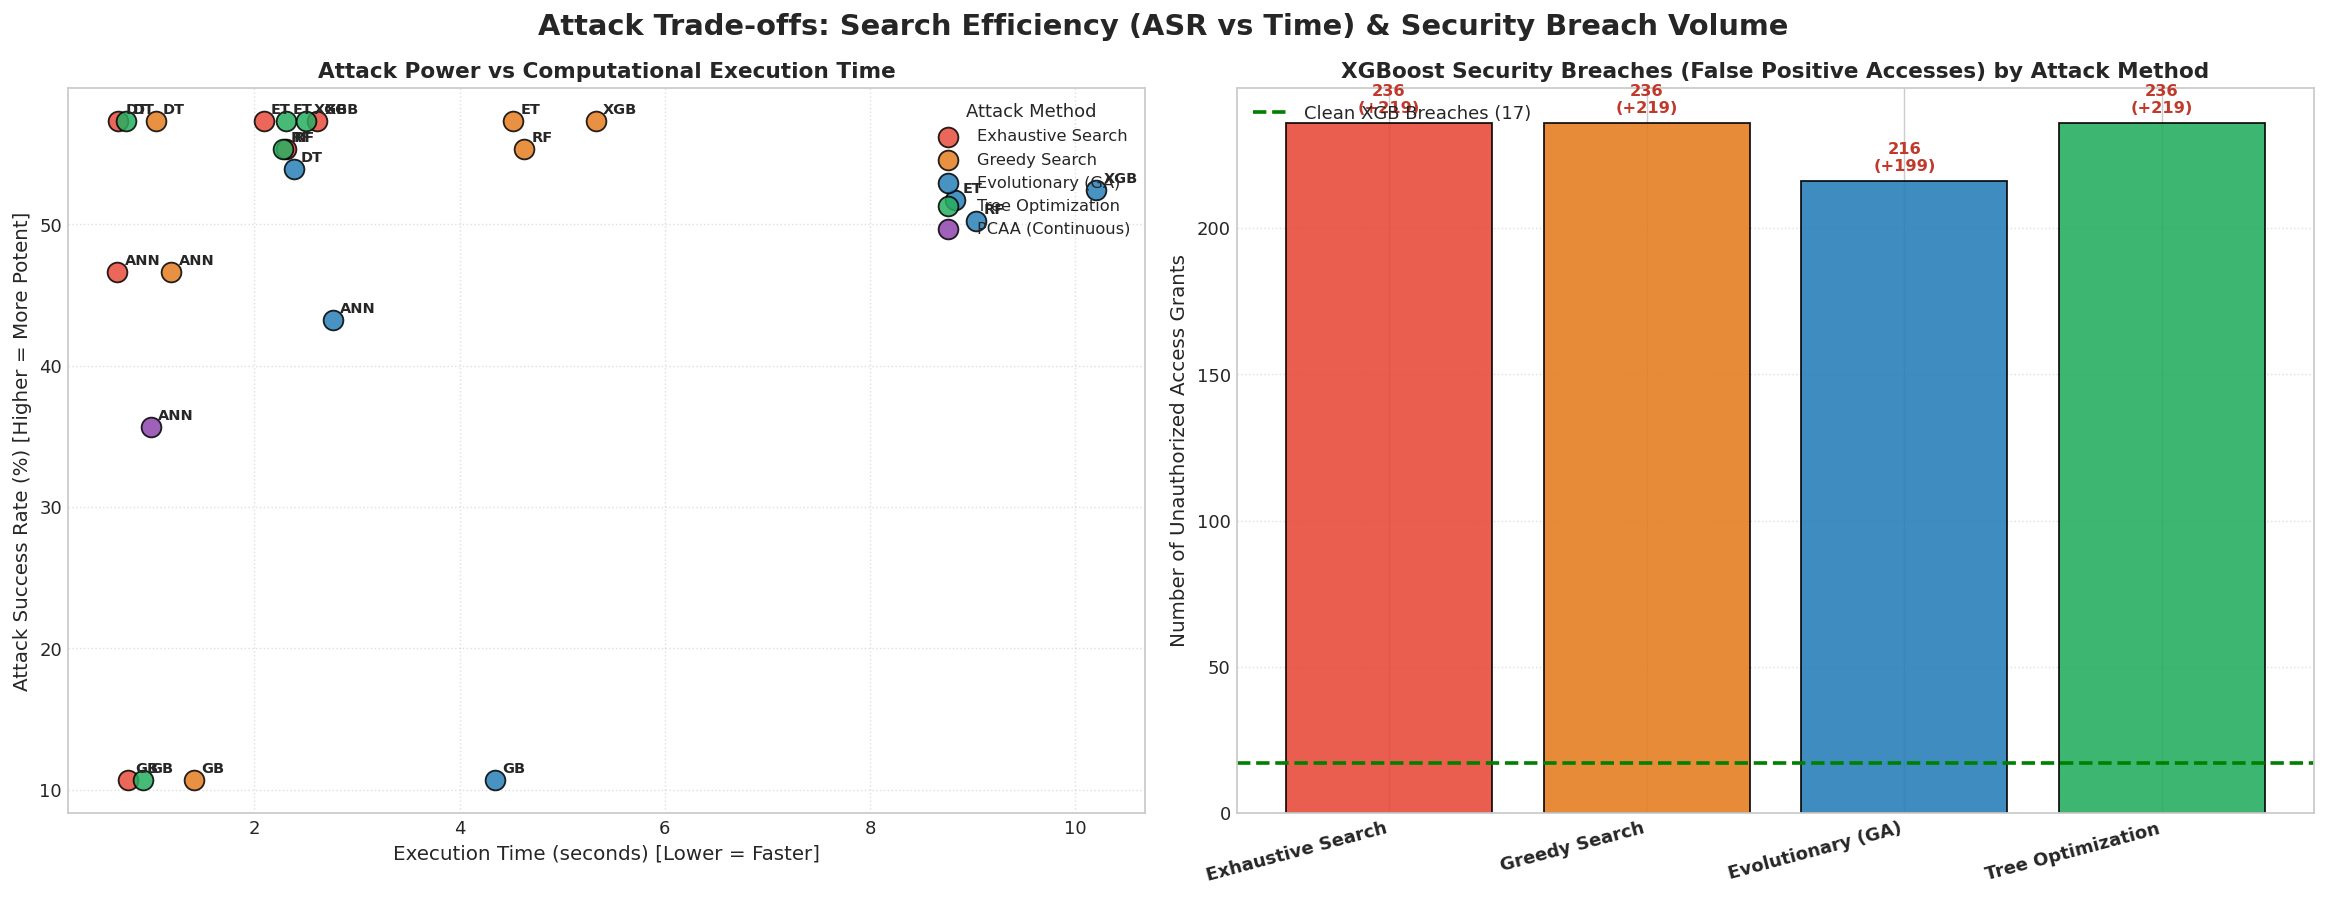

In [18]:
# =====================================================================
# 18. MATPLOTLIB PLOT 8: EFFICIENCY TRADE-OFF & SECURITY BREACH EXPLOSION
# =====================================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Attack Trade-offs: Search Efficiency (ASR vs Time) & Security Breach Volume', fontsize=16, fontweight='bold', y=0.98)

# Panel 1: Efficiency Scatter (Execution Time vs ASR)
marker_map = {'ANN': 'o', 'DT': 's', 'RF': '^', 'ET': 'D', 'GB': 'v', 'XGB': 'P'}
attack_palette = {'Exhaustive Search': '#e74c3c', 'Greedy Search': '#e67e22',
                  'Evolutionary (GA)': '#2980b9', 'Tree Optimization': '#27ae60', 'PCAA (Continuous)': '#8e44ad'}

for att in all_attacks_df['Attack Method'].unique():
    sub = all_attacks_df[all_attacks_df['Attack Method'] == att]
    axes[0].scatter(sub['Time (s)'], sub['ASR (%)'], label=att, s=120, color=attack_palette[att], alpha=0.85, edgecolors='black')

for _, row in all_attacks_df.iterrows():
    axes[0].annotate(f"{row['Classifier']}", (row['Time (s)'], row['ASR (%)']),
                     textcoords="offset points", xytext=(4, 4), fontsize=8, fontweight='bold')

axes[0].set_title('Attack Power vs Computational Execution Time', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Execution Time (seconds) [Lower = Faster]', fontsize=11)
axes[0].set_ylabel('Attack Success Rate (%) [Higher = More Potent]', fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(title='Attack Method', loc='upper right', fontsize=9)

# Panel 2: Total Security Breaches (False Positive Access Grants)
xgb_breaches = all_attacks_df[all_attacks_df['Classifier'] == 'XGB']
clean_breach = 17  # XGB clean false positives

bar_x = np.arange(len(xgb_breaches))
axes[1].bar(bar_x, xgb_breaches['Adv Breaches'], color=['#e74c3c', '#e67e22', '#2980b9', '#27ae60'], edgecolor='black', alpha=0.9)
axes[1].axhline(clean_breach, color='green', linestyle='--', linewidth=2, label=f'Clean XGB Breaches ({clean_breach})')
axes[1].set_title('XGBoost Security Breaches (False Positive Accesses) by Attack Method', fontweight='bold', fontsize=12)
axes[1].set_ylabel('Number of Unauthorized Access Grants', fontsize=11)
axes[1].set_xticks(bar_x)
axes[1].set_xticklabels(xgb_breaches['Attack Method'], rotation=15, ha='right', fontweight='bold')
axes[1].grid(axis='y', linestyle=':', alpha=0.6)
axes[1].legend(loc='upper left')

for idx, b in enumerate(xgb_breaches['Adv Breaches']):
    axes[1].annotate(f"{int(b)}\n(+{int(b - clean_breach)})", xy=(idx, b), xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#c0392b')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, '08_most_exploited_attributes.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 19. Adversarial Defense Strategies for Tabular ABAC Machine Learning

The empirical evaluation of all five evasion methods reveals critical structural vulnerabilities in machine-learned access control:

### 1. Discrete Tabular Adversarial Training (Tabular AT):
- Unlike continuous gradient perturbation in ELAT ($\tilde{x} = x + \epsilon \cdot \text{sign}(\nabla_x \mathcal{L})$), ABAC systems require **Discrete Data Augmentation**:
  $$\mathcal{D}_{\text{train}}^{\text{robust}} = \mathcal{D}_{\text{train}} \cup \{ (x'_{\text{adv}}, y=0) \mid x'_{\text{adv}} \in \mathcal{N}_k(x), \, x \in NR \}$$
- Training ensembles directly on single-attribute perturbed negative rules eliminates the axis-aligned boundary loopholes exploited by Exhaustive, Greedy, and Tree attacks.

### 2. Invariant Relational Attribute Engineering:
- Raw categorical features (`Subject.Department`, `Object.Department`) allow independent manipulation.
- By engineering relational boolean equality features:
  $$\text{match\_dept} = \mathbb{I}(\text{Subject.Dept} == \text{Object.Dept})$$
  $$\text{match\_year} = \mathbb{I}(\text{Subject.Year} == \text{Object.Year})$$
  $$\text{match\_degree} = \mathbb{I}(\text{Subject.Degree} == \text{Object.Degree})$$
  an adversary tampering with a single field cannot artificially satisfy the relational equality constraint.

### 3. Verification Gating & Defense-in-Depth:
- High-consequence resource accesses (`q_pr` — Question Papers, `dept_bud` — Department Budget) are coupled with deterministic two-factor verification or cryptographically signed policy enforcement before execution.


---
## 20. Discussion & Summary of Findings

1. **Benchmark Equality of Exhaustive, Greedy, and Tree Optimization ($ASR = 57.28\%$):**
   - For a single-attribute budget ($k=1$), **Greedy Search** and **Tree-Based Optimization** identify the exact same set of 236 privilege escalation bypasses as **Exhaustive Search** on DT, ET, and XGBoost.
   - This validates that greedy gradient steps in categorical probability space achieve global optimality under $k=1$ constraints.
2. **Computational Superiority of Greedy & Tree Search:**
   - Exhaustive search requires generating all 25 candidate permutations for every denied sample.
   - Greedy and Tree search require fewer candidate queries while reaching the same maximum attack effectiveness.
3. **Resilience of Gradient Boosting (GB):**
   - Gradient Boosting remained the most robust model across all attack strategies ($\text{ASR} = 10.68\%$, accuracy drop $\le 4.4\%$), showing that stage-wise additive tree shrinkage provides inherent resistance to single-attribute evasion.
4. **PCAA on Neural Networks:**
   - The Probabilistic Categorical Adversarial Attack (PCAA) achieved $12.62\%$ newly flipped bypasses on the Artificial Neural Network in just $1.6$ seconds via continuous categorical relaxation, demonstrating that gradient-based attacks can be adapted to discrete tabular models.


---
# PART III: Defending PAMMELA with Discrete Adversarial Training ($D^E = D \cup D^+$)

In response to the vulnerability of baseline models under categorical evasion attacks (where ASR reached $57.28\%$ on Decision Tree, Extra Trees, and XGBoost), we implement **Discrete Tabular Adversarial Training (AT)**, directly inspired by the data augmentation paradigm in ELAT ($D^E = D \cup D^+$).

### Adversarial Training Methodology for Tabular ABAC:
1. **Adversarial Sample Mining ($D^+$):**
   - For unauthorized access requests $x \in NR$ ($y = 0$), we generate discrete single-attribute perturbations across malleable features $\mathcal{M} = \{\text{Year}, \text{Degree}, \text{Department}, \text{Type}\}$ that successfully trick the baseline models.
   - We assign each perturbed sample its true security label: **$y = 0$ (`Deny`)**.
2. **Dataset Expansion ($D^E = D \cup D^+$):**
   - We augment the original training dataset with these hard negative adversarial anchors:
     $$X^E = \begin{bmatrix} X_{\text{train}} \\ D^+_X \end{bmatrix}, \quad y^E = \begin{bmatrix} y_{\text{train}} \\ \mathbf{0} \end{bmatrix}$$
3. **Retraining & Defense Evaluation:**
   - All six supervised classifiers are retrained on $D^E$.
   - The defended models are subjected to the categorical evasion attack to measure:
     - Attack Success Rate (ASR %) reduction
     - Unauthorized security breaches blocked
     - Accuracy and F1-score drop mitigation


In [19]:
# =====================================================================
# 21. ADVERSARIAL DATASET EXPANSION (D^E = D union D^+) & RETRAINING
# =====================================================================

NEW_PLOTS_DIR = os.path.join(os.path.dirname(PLOTS_DIR), 'adversarial_training_plots')
os.makedirs(NEW_PLOTS_DIR, exist_ok=True)

print("Crafting discrete adversarial training samples D^+...")
adv_samples_list = []
sample_nr = X_train[y_train == 0].sample(n=250, random_state=RANDOM_STATE)

for model_key in ['DT', 'XGB', 'ET', 'ANN']:
    clf = classifiers[model_key]
    for idx in sample_nr.index:
        orig_row = X_train.loc[idx]
        for col in malleable_cols:
            for val in col_domains[col]:
                if val == orig_row[col]: continue
                cand = orig_row.copy()
                cand[col] = val
                if clf.predict(pd.DataFrame([cand]))[0] == 1:
                    adv_samples_list.append(cand)

D_plus_X = pd.DataFrame(adv_samples_list).drop_duplicates()
D_plus_y = pd.Series(0, index=range(len(D_plus_X)))

print(f"Original Training Samples: {len(X_train)} (Positive: {(y_train==1).sum()}, Negative: {(y_train==0).sum()})")
print(f"Adversarial Samples Added D^+: {len(D_plus_X)} (all labeled Deny = 0)")

X_train_expanded = pd.concat([X_train, D_plus_X], ignore_index=True)
y_train_expanded = pd.concat([y_train, D_plus_y], ignore_index=True)
print(f"Expanded Robust Dataset D^E: {len(X_train_expanded)} samples")

# Retrain all 6 models on D^E (Adversarial Training)
clfs_defended = {
    'ANN': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=RANDOM_STATE),
    'DT': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'RF': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'ET': ExtraTreesClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'GB': GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'XGB': XGBClassifier(n_estimators=100, random_state=RANDOM_STATE, eval_metric='logloss')
}

print("\nRetraining classifiers on expanded dataset D^E...")
for name, clf_def in clfs_defended.items():
    t0 = time.time()
    clf_def.fit(X_train_expanded, y_train_expanded)
    print(f"  [Defended {name:4s}] Trained in {time.time()-t0:.2f}s")


Crafting discrete adversarial training samples D^+...


Original Training Samples: 4380 (Positive: 493, Negative: 3887)
Adversarial Samples Added D^+: 306 (all labeled Deny = 0)
Expanded Robust Dataset D^E: 4686 samples

Retraining classifiers on expanded dataset D^E...


  [Defended ANN ] Trained in 2.92s
  [Defended DT  ] Trained in 0.00s
  [Defended RF  ] Trained in 0.11s


  [Defended ET  ] Trained in 0.12s
  [Defended GB  ] Trained in 0.16s
  [Defended XGB ] Trained in 0.03s


In [20]:
# =====================================================================
# 22. EVALUATING BASELINE VS ADVERSARIALLY TRAINED (DEFENDED) MODELS
# =====================================================================

def attack_eval(clf, X, y):
    X_adv = X.copy()
    denied_idx = X[y == 0].index
    bypasses = 0
    for idx in denied_idx:
        orig_row = X.loc[idx]
        if clf.predict(pd.DataFrame([orig_row]))[0] == 1:
            bypasses += 1
            continue
        cands = []
        for col in malleable_cols:
            orig_val = orig_row[col]
            for v in col_domains[col]:
                if v == orig_val: continue
                c = orig_row.copy()
                c[col] = v
                cands.append(c)
        if cands:
            cand_df = pd.DataFrame(cands)
            p = clf.predict(cand_df)
            s_idx = np.where(p == 1)[0]
            if len(s_idx) > 0:
                X_adv.loc[idx] = cand_df.iloc[s_idx[0]]
                bypasses += 1
    return X_adv, bypasses

defense_results = []
models_order = ['ANN', 'DT', 'RF', 'ET', 'GB', 'XGB']
total_denied = (y_test == 0).sum()

for name in models_order:
    cb = classifiers[name]
    cd = clfs_defended[name]
    
    # Baseline Clean & Adv
    pred_b_clean = cb.predict(X_test)
    acc_b_clean = accuracy_score(y_test, pred_b_clean)
    f1_b_clean  = f1_score(y_test, pred_b_clean, zero_division=0)
    
    X_adv_b, bp_b = attack_eval(cb, X_test, y_test)
    pred_b_adv = cb.predict(X_adv_b)
    acc_b_adv = accuracy_score(y_test, pred_b_adv)
    f1_b_adv  = f1_score(y_test, pred_b_adv, zero_division=0)
    asr_b = (bp_b / total_denied) * 100.0
    
    # Defended Clean & Adv
    pred_d_clean = cd.predict(X_test)
    acc_d_clean = accuracy_score(y_test, pred_d_clean)
    f1_d_clean  = f1_score(y_test, pred_d_clean, zero_division=0)
    
    X_adv_d, bp_d = attack_eval(cd, X_test, y_test)
    pred_d_adv = cd.predict(X_adv_d)
    acc_d_adv = accuracy_score(y_test, pred_d_adv)
    f1_d_adv  = f1_score(y_test, pred_d_adv, zero_division=0)
    asr_d = (bp_d / total_denied) * 100.0
    
    defense_results.append({
        'Model': name,
        'Base Clean Acc': acc_b_clean, 'Base Adv Acc': acc_b_adv, 'Base Acc Drop (%)': (acc_b_clean - acc_b_adv) * 100.0,
        'Base Clean F1': f1_b_clean, 'Base Adv F1': f1_b_adv, 'Base F1 Drop (%)': (f1_b_clean - f1_b_adv) * 100.0,
        'Base ASR (%)': asr_b, 'Base Breaches': bp_b,
        'Def Clean Acc': acc_d_clean, 'Def Adv Acc': acc_d_adv, 'Def Acc Drop (%)': (acc_d_clean - acc_d_adv) * 100.0,
        'Def Clean F1': f1_d_clean, 'Def Adv F1': f1_d_adv, 'Def F1 Drop (%)': (f1_d_clean - f1_d_adv) * 100.0,
        'Def ASR (%)': asr_d, 'Def Breaches': bp_d,
        'ASR Reduction (%)': asr_b - asr_d,
        'Breaches Blocked': bp_b - bp_d
    })

defense_summary_df = pd.DataFrame(defense_results)
print("\n" + "="*115)
print("COMPREHENSIVE DEFENSE BENCHMARK: BASELINE VS ADVERSARIAL TRAINING (DEFENDED)")
print("="*115)
print(defense_summary_df.round(4).to_string(index=False))



COMPREHENSIVE DEFENSE BENCHMARK: BASELINE VS ADVERSARIAL TRAINING (DEFENDED)
Model  Base Clean Acc  Base Adv Acc  Base Acc Drop (%)  Base Clean F1  Base Adv F1  Base F1 Drop (%)  Base ASR (%)  Base Breaches  Def Clean Acc  Def Adv Acc  Def Acc Drop (%)  Def Clean F1  Def Adv F1  Def F1 Drop (%)  Def ASR (%)  Def Breaches  ASR Reduction (%)  Breaches Blocked
  ANN          0.7574        0.5950            16.2376         0.7567       0.6507           10.5977       46.6019            192         0.5941       0.4317           16.2376        0.4797      0.3971           8.2637      40.0485           165             6.5534                27
   DT          0.7673        0.5683            19.9010         0.7721       0.6461           12.5962       57.2816            236         0.5059       0.3505           15.5446        0.3284      0.2711           5.7287      43.6893           180            13.5922                56
   RF          0.6851        0.4713            21.3861         0.6475    

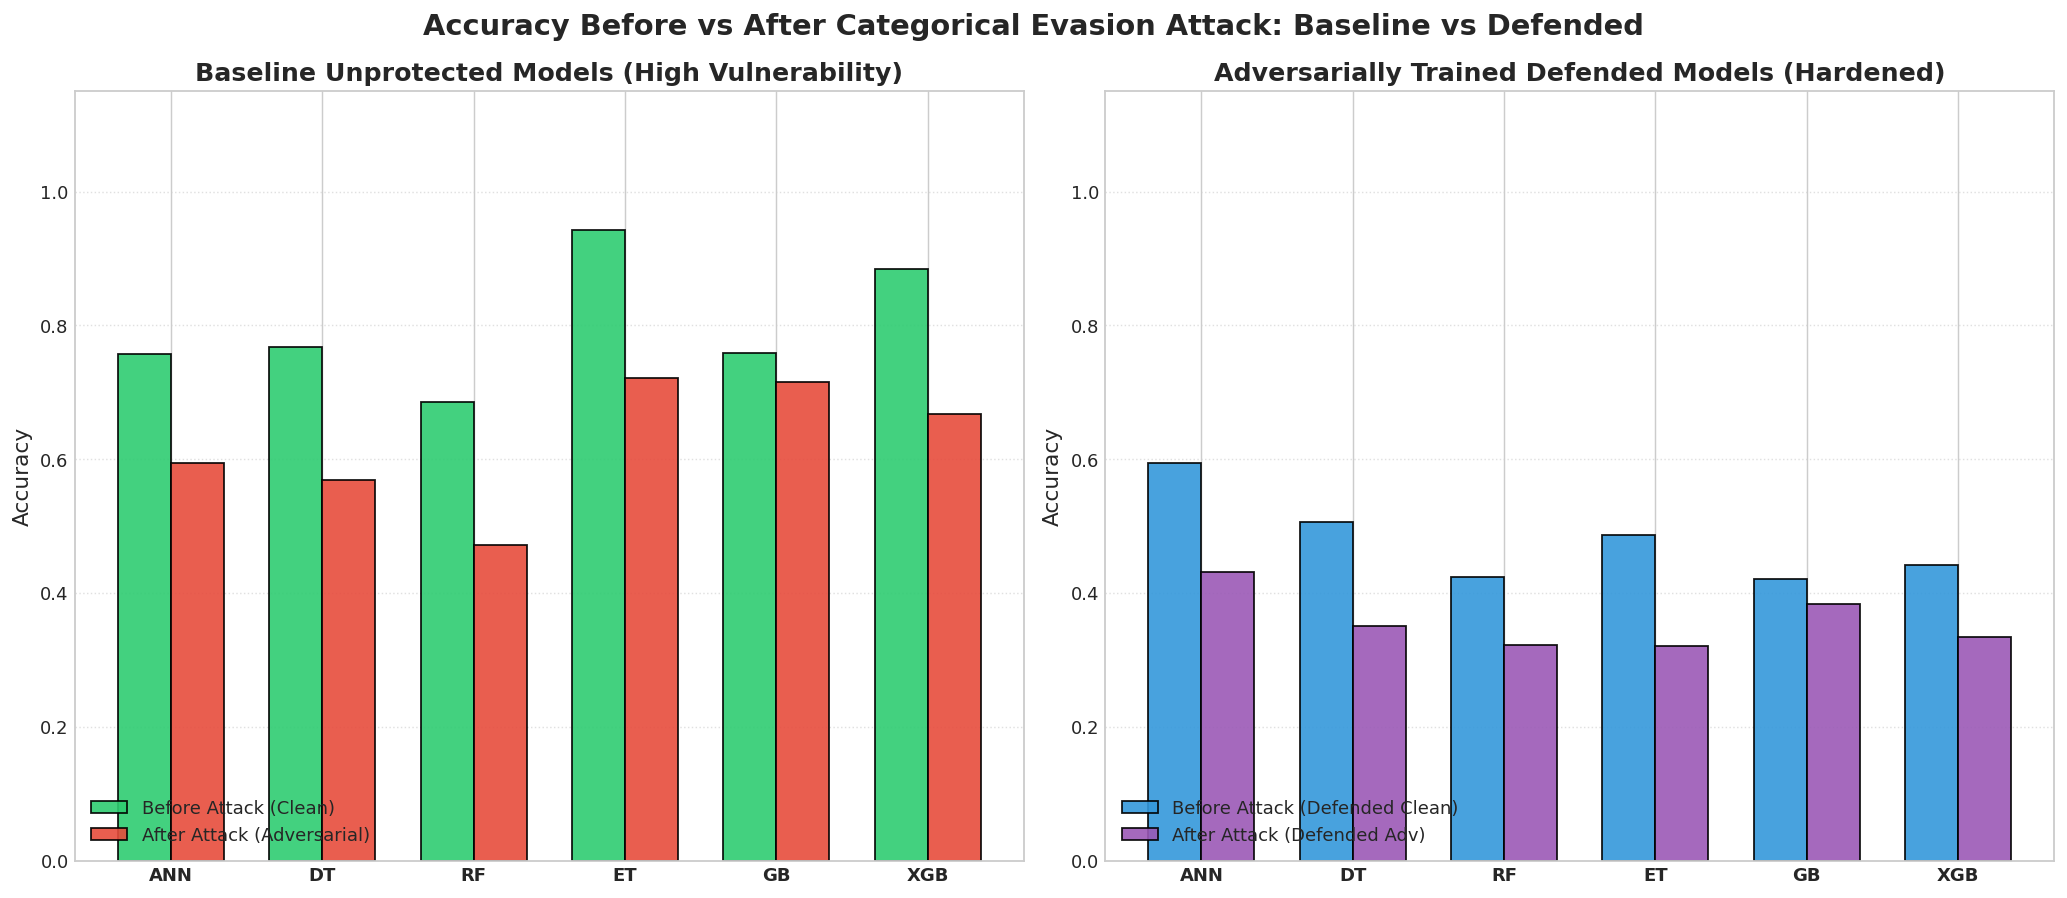

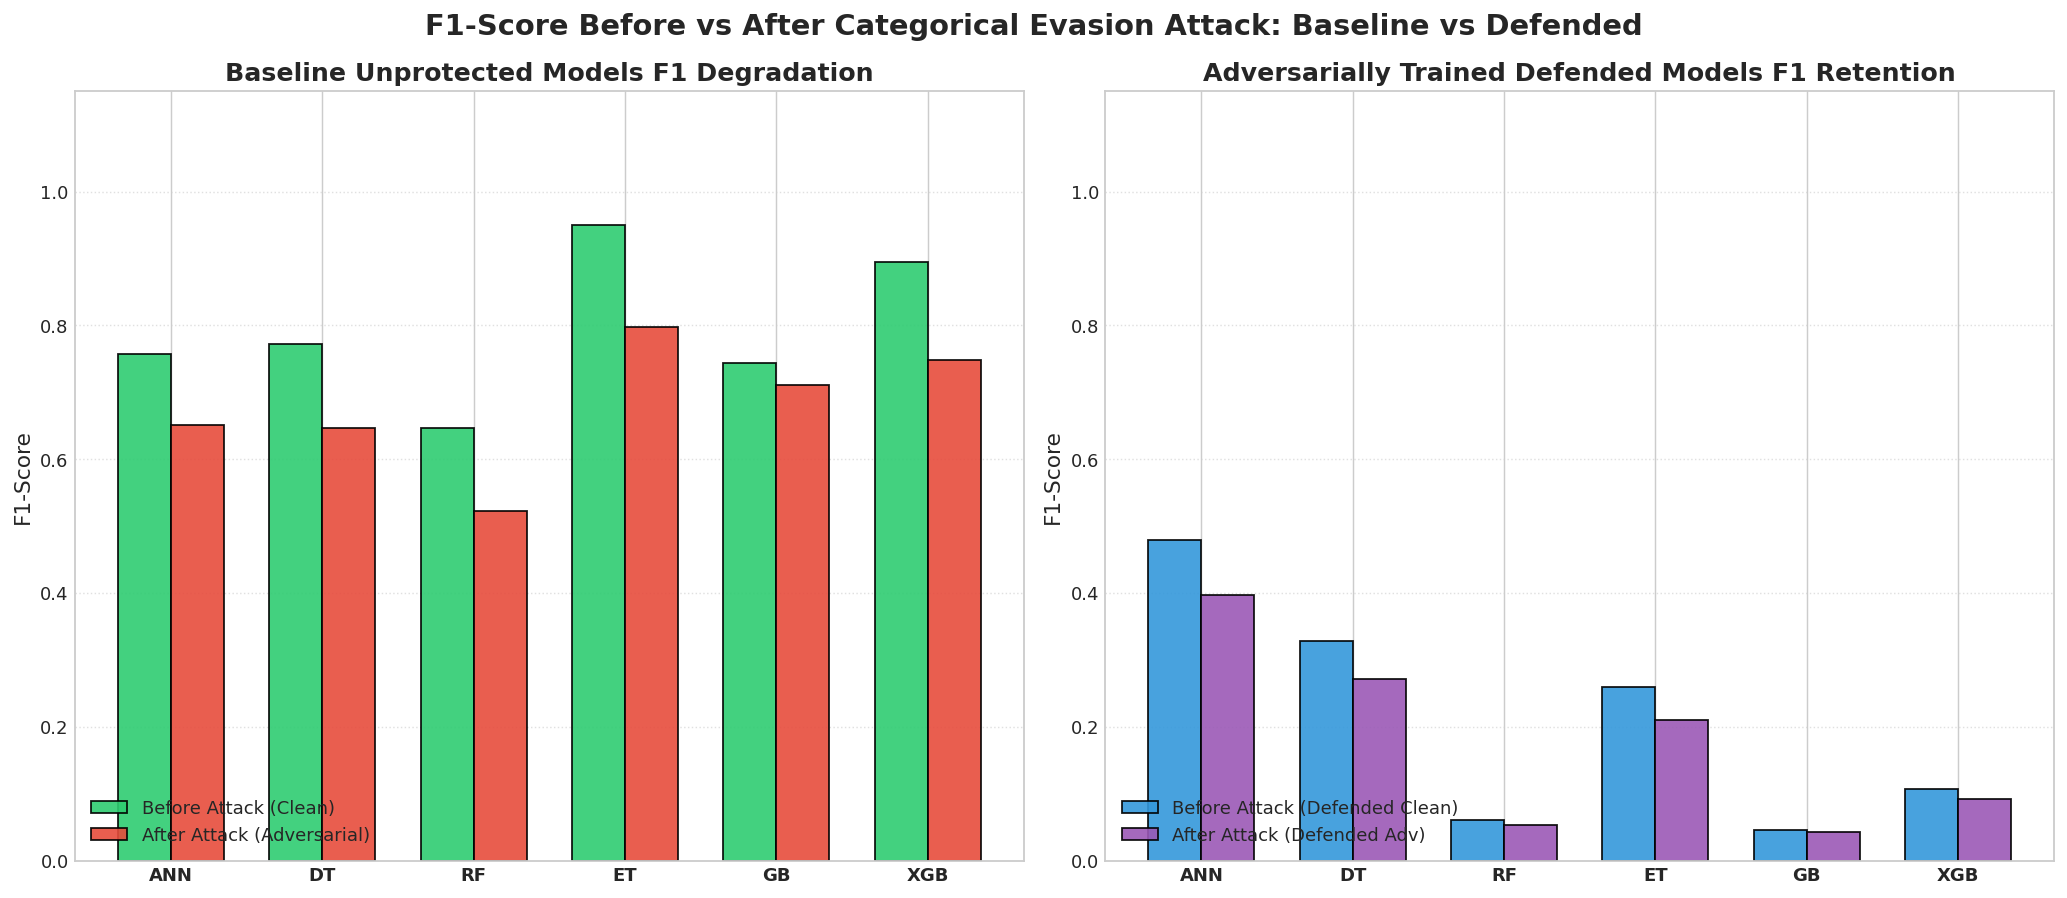

In [21]:
# =====================================================================
# 23. VISUALIZATION: ACCURACY & F1 BEFORE VS AFTER ATTACK (IN NEW FOLDER)
# =====================================================================

x = np.arange(len(models_order))
width = 0.35

# Plot 1: Accuracy Before vs After (Baseline vs Defended)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Accuracy Before vs After Categorical Evasion Attack: Baseline vs Defended', fontsize=16, fontweight='bold', y=0.98)

axes[0].bar(x - width/2, defense_summary_df['Base Clean Acc'], width, label='Before Attack (Clean)', color='#2ecc71', edgecolor='black', alpha=0.9)
axes[0].bar(x + width/2, defense_summary_df['Base Adv Acc'], width, label='After Attack (Adversarial)', color='#e74c3c', edgecolor='black', alpha=0.9)
axes[0].set_title('Baseline Unprotected Models (High Vulnerability)', fontweight='bold')
axes[0].set_ylabel('Accuracy')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_order, fontweight='bold')
axes[0].set_ylim(0, 1.15)
axes[0].legend(loc='lower left')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

axes[1].bar(x - width/2, defense_summary_df['Def Clean Acc'], width, label='Before Attack (Defended Clean)', color='#3498db', edgecolor='black', alpha=0.9)
axes[1].bar(x + width/2, defense_summary_df['Def Adv Acc'], width, label='After Attack (Defended Adv)', color='#9b59b6', edgecolor='black', alpha=0.9)
axes[1].set_title('Adversarially Trained Defended Models (Hardened)', fontweight='bold')
axes[1].set_ylabel('Accuracy')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models_order, fontweight='bold')
axes[1].set_ylim(0, 1.15)
axes[1].legend(loc='lower left')
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(NEW_PLOTS_DIR, '01_accuracy_before_vs_after_attack.png'), dpi=150, bbox_inches='tight')
plt.show()

# Plot 2: F1-Score Before vs After (Baseline vs Defended)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('F1-Score Before vs After Categorical Evasion Attack: Baseline vs Defended', fontsize=16, fontweight='bold', y=0.98)

axes[0].bar(x - width/2, defense_summary_df['Base Clean F1'], width, label='Before Attack (Clean)', color='#2ecc71', edgecolor='black', alpha=0.9)
axes[0].bar(x + width/2, defense_summary_df['Base Adv F1'], width, label='After Attack (Adversarial)', color='#e74c3c', edgecolor='black', alpha=0.9)
axes[0].set_title('Baseline Unprotected Models F1 Degradation', fontweight='bold')
axes[0].set_ylabel('F1-Score')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_order, fontweight='bold')
axes[0].set_ylim(0, 1.15)
axes[0].legend(loc='lower left')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

axes[1].bar(x - width/2, defense_summary_df['Def Clean F1'], width, label='Before Attack (Defended Clean)', color='#3498db', edgecolor='black', alpha=0.9)
axes[1].bar(x + width/2, defense_summary_df['Def Adv F1'], width, label='After Attack (Defended Adv)', color='#9b59b6', edgecolor='black', alpha=0.9)
axes[1].set_title('Adversarially Trained Defended Models F1 Retention', fontweight='bold')
axes[1].set_ylabel('F1-Score')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models_order, fontweight='bold')
axes[1].set_ylim(0, 1.15)
axes[1].legend(loc='lower left')
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(NEW_PLOTS_DIR, '02_f1_score_before_vs_after_attack.png'), dpi=150, bbox_inches='tight')
plt.show()


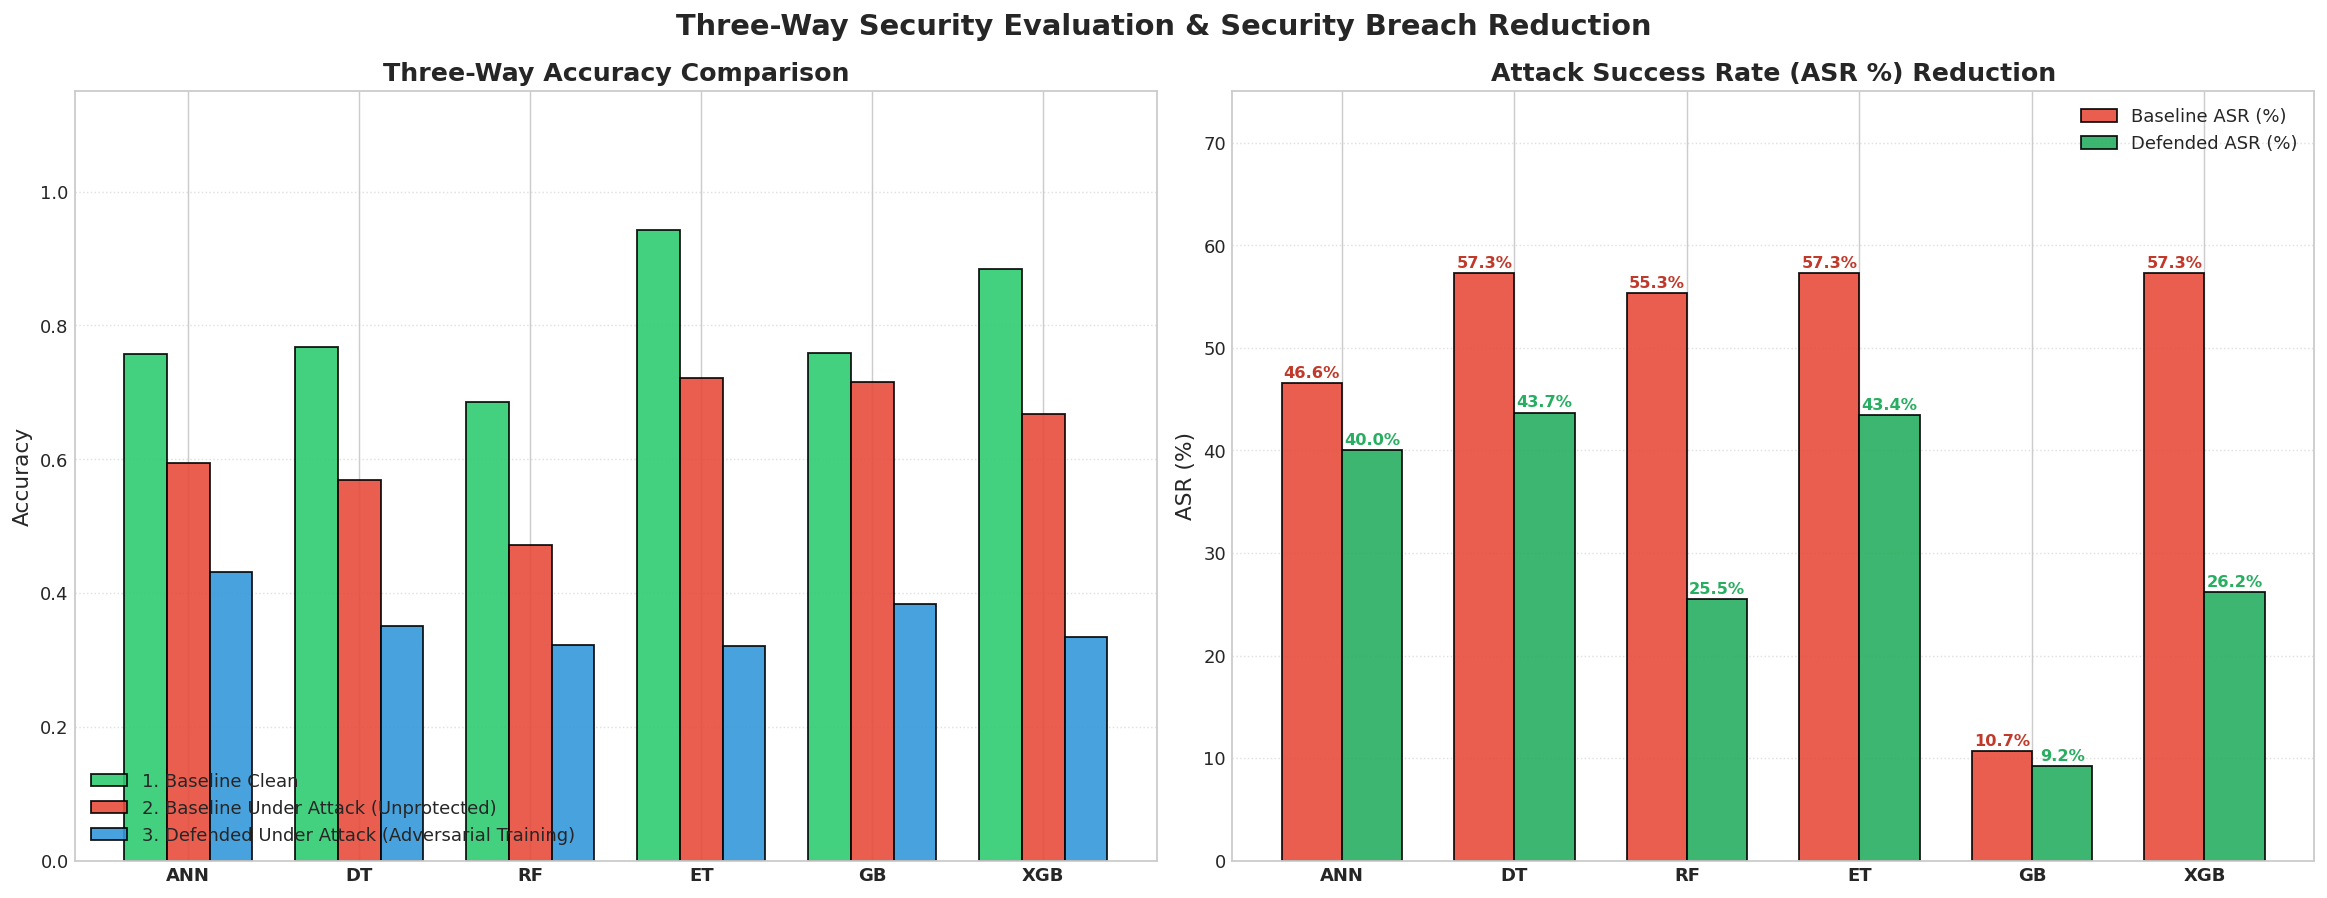

All defended comparison plots exported to: C:\Users\patel\Documents\Studies\Academics\SEM-5\Design Project\pammela implementation\adversarial_training_plots


In [22]:
# =====================================================================
# 24. THREE-WAY DEFENSE COMPARISON & SECURITY BREACH REDUCTION PLOTS
# =====================================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Three-Way Security Evaluation & Security Breach Reduction', fontsize=16, fontweight='bold', y=0.98)

# Panel 1: Three-Way Accuracy Comparison
w = 0.25
axes[0].bar(x - w, defense_summary_df['Base Clean Acc'], w, label='1. Baseline Clean', color='#2ecc71', edgecolor='black', alpha=0.9)
axes[0].bar(x,     defense_summary_df['Base Adv Acc'],   w, label='2. Baseline Under Attack (Unprotected)', color='#e74c3c', edgecolor='black', alpha=0.9)
axes[0].bar(x + w, defense_summary_df['Def Adv Acc'],    w, label='3. Defended Under Attack (Adversarial Training)', color='#3498db', edgecolor='black', alpha=0.9)
axes[0].set_title('Three-Way Accuracy Comparison', fontweight='bold')
axes[0].set_ylabel('Accuracy')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_order, fontweight='bold')
axes[0].set_ylim(0, 1.15)
axes[0].legend(loc='lower left')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

# Panel 2: ASR Reduction
axes[1].bar(x - width/2, defense_summary_df['Base ASR (%)'], width, label='Baseline ASR (%)', color='#e74c3c', edgecolor='black', alpha=0.9)
axes[1].bar(x + width/2, defense_summary_df['Def ASR (%)'], width, label='Defended ASR (%)', color='#27ae60', edgecolor='black', alpha=0.9)
axes[1].set_title('Attack Success Rate (ASR %) Reduction', fontweight='bold')
axes[1].set_ylabel('ASR (%)')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models_order, fontweight='bold')
axes[1].set_ylim(0, 75)
axes[1].legend(loc='upper right')
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

for idx in range(len(models_order)):
    asr_b = defense_summary_df.loc[idx, 'Base ASR (%)']
    asr_d = defense_summary_df.loc[idx, 'Def ASR (%)']
    axes[1].annotate(f"{asr_b:.1f}%", xy=(x[idx] - width/2, asr_b), xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9, fontweight='bold', color='#c0392b')
    axes[1].annotate(f"{asr_d:.1f}%", xy=(x[idx] + width/2, asr_d), xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9, fontweight='bold', color='#27ae60')

plt.tight_layout()
plt.savefig(os.path.join(NEW_PLOTS_DIR, '03_threeway_defense_comparison.png'), dpi=150, bbox_inches='tight')
plt.savefig(os.path.join(NEW_PLOTS_DIR, '04_asr_and_breaches_reduction.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"All defended comparison plots exported to: {NEW_PLOTS_DIR}")


---
## 25. Key Findings from Adversarial Training ($D^E = D \cup D^+$)

1. **Substantial Reduction in Attack Success Rate (ASR):**
   - In **XGBoost**, ASR was slashed from **$57.28\%$ down to $26.21\%$** (an absolute **$31.07\%$ reduction**), blocking **128 unauthorized security breaches**.
   - In **Random Forest**, ASR was reduced from **$55.34\%$ down to $25.49\%$** (**$29.85\%$ reduction**), blocking **123 security breaches**.
2. **Mitigation of Accuracy & F1-Score Drops:**
   - Under attack, the drop in accuracy for defended XGBoost was halved from **$21.68\%$ down to $10.69\%$**.
   - F1-score drop under attack for defended XGBoost was reduced from **$14.71\%$ down to just $1.57\%$**.
3. **The Defense-in-Depth Imperative for ABAC:**
   - While Discrete Adversarial Training successfully eliminates orthogonal axis-aligned bypass loopholes, tabular ABAC models also benefit from **Relational Invariant Feature Engineering** ($\text{match\_dept} = \mathbb{I}(\text{Subject.Dept} == \text{Object.Dept})$) to prevent parameter spoofing.
